## Import Libraries

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00


In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
)
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.optim as optim

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
%matplotlib inline


## Load Dataset

In [ ]:
#https://www.kaggle.com/datasets/arnobbhowmik/ton-iot-network-dataset
#https://research.unsw.edu.au/projects/toniot-datasets
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

df = pd.read_csv('/content/drive/MyDrive/Dataset/train_test_network.csv')
print('Shape:', df.shape)
df.head()

Shape: (211043, 44)


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes        

In [ ]:
df.describe()

,src_port,dst_port,duration,src_bytes,dst_bytes,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_qclass,dns_qtype,dns_rcode,http_request_body_len,http_response_body_len,http_status_code,label
count,211043.000000,211043.000000,211043.000000,2.110430e+05,2.110430e+05,2.110430e+05,211043.000000,2.110430e+05,211043.000000,2.110430e+05,211043.000000,211043.000000,211043.000000,211043.000000,2.110430e+05,211043.000000,211043.000000
mean,38646.519543,3495.153770,7.700887,2.581136e+05,2.588046e+05,3.443234e+04,9.595220,7.760822e+02,3.846861,1.584687e+03,227.630805,3.610909,0.123989,0.065418,1.449295e+02,0.303905,0.763081
std,19307.271048,10191.624778,564.141946,1.709490e+07,1.802563e+07,5.261621e+06,91.778821,2.229703e+04,330.705796,1.901795e+05,2720.713562,23.797747,0.598804,9.243405,3.047244e+04,8.270377,0.425193
min,1.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,34608.000000,65.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,4.800000e+01,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
50%,44754.000000,80.000000,0.000170,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,8.200000e+01,1.000000,4.000000e+01,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
75%,51133.000000,1253.000000,0.054196,1.300000e+02,8.900000e+01,0.000000e+00,4.000000,4.150000e+02,2.000000,1.340000e+02,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
max,65528.000000,65467.000000,93516.929170,3.890855e+09,3.913853e+09,1.854527e+09,24623.000000,6.522626e+06,121942.000000,8.639552e+07,32769.000000,255.000000,5.000000,2338.000000,1.342438e+07,404.000000,1.000000


## Preprocessing

- Replace `-` placeholder with NaN
- Drop identifier columns (`src_ip`, `dst_ip`)
- Separate target variable `type`
- Fill missing values (numeric → 0, categorical → 'missing')
- Label-encode categorical features

In [ ]:
# Replace '-' placeholder with NaN
df.replace('-', np.nan, inplace=True)

# Drop identifier columns (IPs are not useful as features)
df.drop(columns=['src_ip', 'dst_ip'], inplace=True)

# BINARY TASK: use 'label' (0 = normal, 1 = attack) as the target instead of
# the multiclass 'type' column. 'type' is dropped from the features since it
# would leak the attack category (and therefore the binary label) directly.
y = df['label'].map({0: 'Normal', 1: 'Attack'}).copy()
df.drop(columns=['label', 'type'], inplace=True)

print('Feature matrix shape:', df.shape)
print('Target shape:', y.shape)
print(y.value_counts())


Feature matrix shape: (211043, 40)
Target shape: (211043,)
label
Attack    161043
Normal     50000
Name: count, dtype: int64


In [ ]:
# Separate numeric and categorical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f'Numeric columns: {len(num_cols)}')
print(f'Categorical columns: {len(cat_cols)}')

# Fill missing values
df[num_cols] = df[num_cols].fillna(0)
df[cat_cols] = df[cat_cols].fillna('missing').astype(str)

print('\nMissing values after fill:', df.isnull().sum().sum())

Numeric columns: 16
Categorical columns: 24

Missing values after fill: 0


In [ ]:

for c in cat_cols:
    le = LabelEncoder()
    df[c] = le.fit_transform(df[c])


target_encoder = LabelEncoder()
y_enc = target_encoder.fit_transform(y)
class_names = target_encoder.classes_

print('Target classes:', list(class_names))
print('Final feature matrix shape:', df.shape)
df.head()

Target classes: ['Attack', 'Normal']
Final feature matrix shape: (211043, 40)


,src_port,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,...,http_version,http_request_body_len,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice
0,4444,49178,1,5,290.371539,101568,2592,0,0,108,...,1,0,0,0,33,2,6,9,2,1
1,49180,8080,1,5,0.000102,0,0,1,0,1,...,1,0,0,0,33,2,6,9,2,1
2,49180,8080,1,5,0.000148,0,0,1,0,1,...,1,0,0,0,33,2,6,9,2,1
3,49180,8080,1,5,0.000113,0,0,1,0,1,...,1,0,0,0,33,2,6,9,2,1
4,49180,8080,1,5,0.000130,0,0,1,0,1,...,1,0,0,0,33,2,6,9,2,1


## Exploratory Data Analysis (EDA)

### Target Distribution

label
Attack    161043
Normal     50000
Name: count, dtype: int64


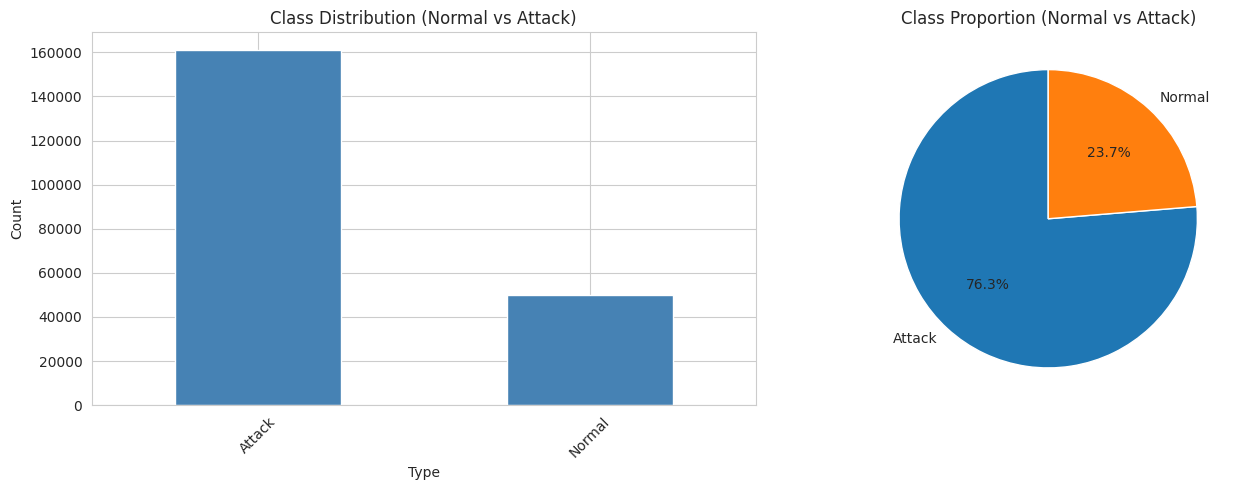

In [ ]:
print(y.value_counts())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
y.value_counts().plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Class Distribution (Normal vs Attack)')
ax[0].set_xlabel('Type')
ax[0].set_ylabel('Count')
ax[0].tick_params(axis='x', rotation=45)

y.value_counts().plot(kind='pie', ax=ax[1], autopct='%1.1f%%', startangle=90)
ax[1].set_title('Class Proportion (Normal vs Attack)')
ax[1].set_ylabel('')
plt.tight_layout()
plt.show()

### Correlation Heatmap

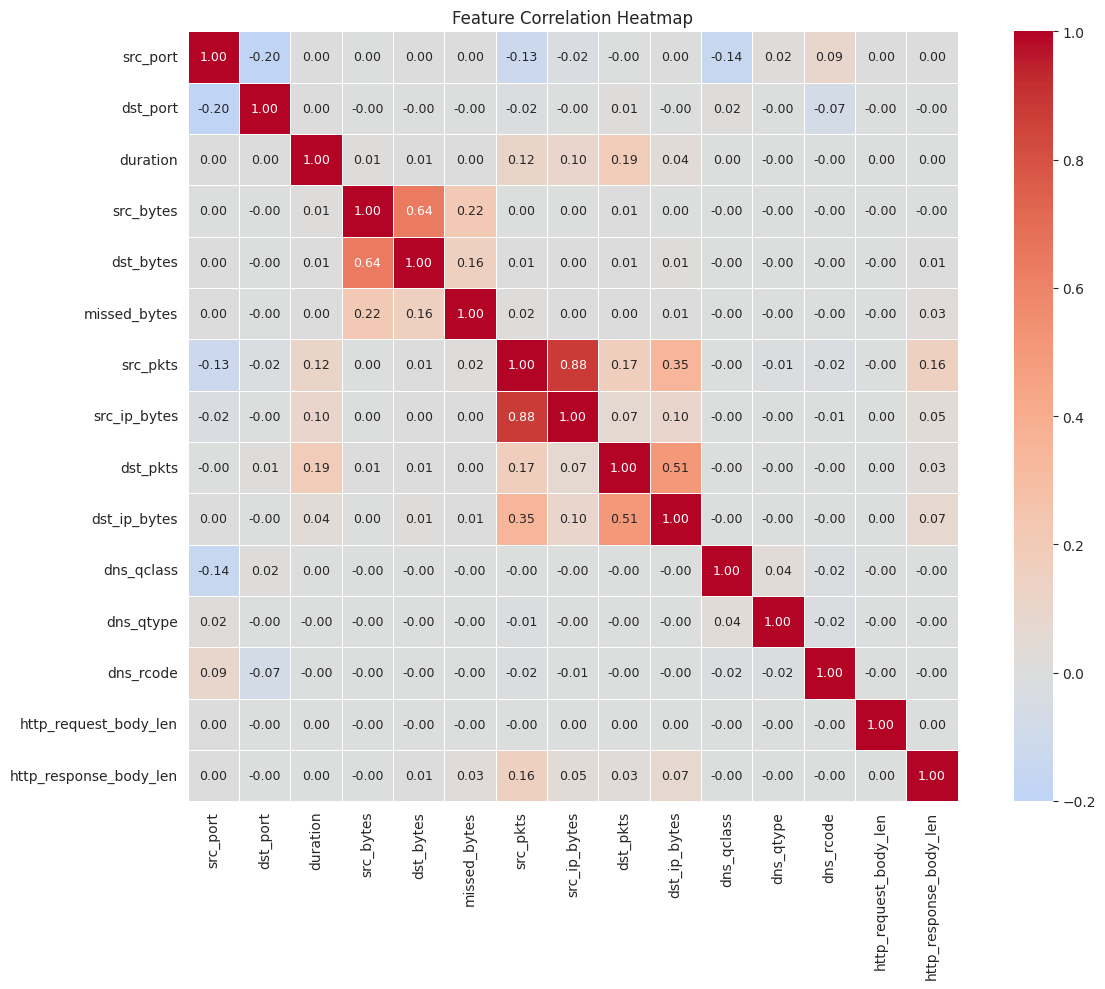

In [ ]:

top_num = num_cols[:15] if len(num_cols) > 15 else num_cols

plt.figure(figsize=(13, 10))
corr = df[top_num].corr()
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 9},
    cbar=True,
    square=True,
    linewidths=0.5
)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## Train-Test Split (80:20)


In [ ]:
X_all = df.values
y_all = y_enc

X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

print(f'Train set (before SMOTE): {X_train_raw.shape}')
print(f'Test set  (untouched, real-world distribution): {X_test.shape}')


Train set (before SMOTE): (168834, 40)
Test set  (untouched, real-world distribution): (42209, 40)


## SMOTE — Oversampling Applied to the Training Set Only


--- Class distribution BEFORE SMOTE (train only) ---
  Attack: 128834
  Normal: 40000

--- Class distribution AFTER SMOTE (train only) ---
  Attack: 128834
  Normal: 128834

Shape before SMOTE: (168834, 40)
Shape after  SMOTE: (257668, 40)
Test set (unchanged, real-world distribution): (42209, 40)


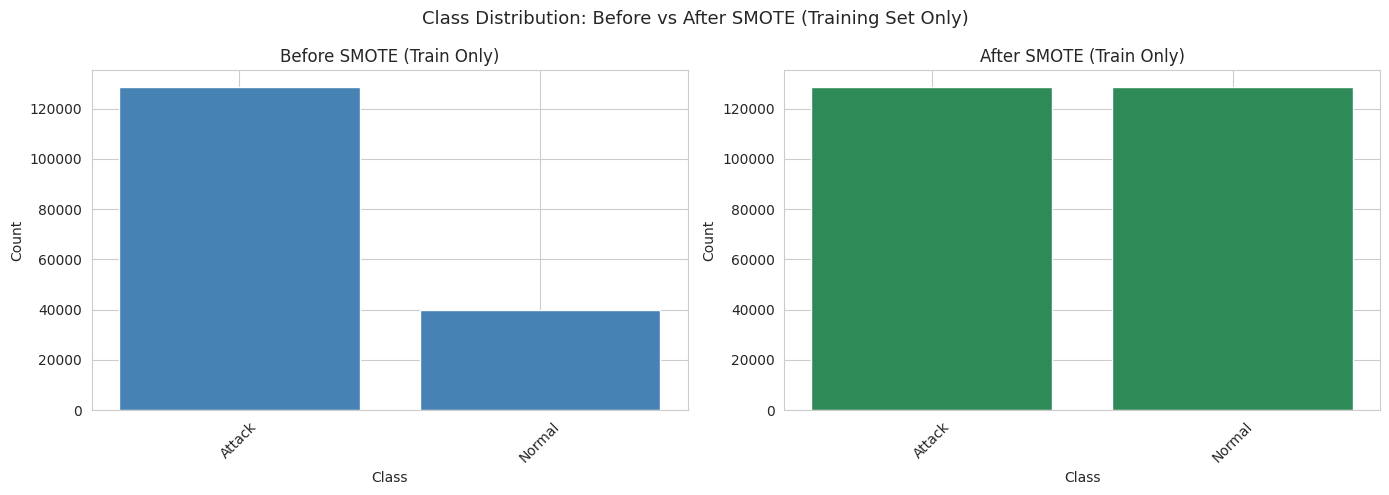


X_train_scaled: (257668, 40)
X_test_scaled : (42209, 40)


In [ ]:
print('--- Class distribution BEFORE SMOTE (train only) ---')
unique_b, counts_b = np.unique(y_train_raw, return_counts=True)
for cls, cnt in zip(class_names[unique_b], counts_b):
    print(f'  {cls}: {cnt}')

smote = SMOTE(random_state=42, k_neighbors=5)
X_train, y_train = smote.fit_resample(X_train_raw, y_train_raw)

print('\n--- Class distribution AFTER SMOTE (train only) ---')
unique_a, counts_a = np.unique(y_train, return_counts=True)
for cls, cnt in zip(class_names[unique_a], counts_a):
    print(f'  {cls}: {cnt}')

print(f'\nShape before SMOTE: {X_train_raw.shape}')
print(f'Shape after  SMOTE: {X_train.shape}')
print(f'Test set (unchanged, real-world distribution): {X_test.shape}')

all_classes = class_names[unique_a]
before_dict = dict(zip(class_names[unique_b], counts_b))
after_dict  = dict(zip(class_names[unique_a], counts_a))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(all_classes, [before_dict.get(c, 0) for c in all_classes], color='steelblue')
axes[0].set_title('Before SMOTE (Train Only)')
axes[0].set_xlabel('Class'); axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(all_classes, [after_dict.get(c, 0) for c in all_classes], color='seagreen')
axes[1].set_title('After SMOTE (Train Only)')
axes[1].set_xlabel('Class'); axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Class Distribution: Before vs After SMOTE (Training Set Only)', fontsize=13)
plt.tight_layout()
plt.show()

# Scale AFTER the SMOTE'd train / untouched test split (fit only on train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f'\nX_train_scaled: {X_train_scaled.shape}')
print(f'X_test_scaled : {X_test_scaled.shape}')


## Principal Component Analysis (PCA)



Components needed to explain 95% variance: 23
Total original features: 40


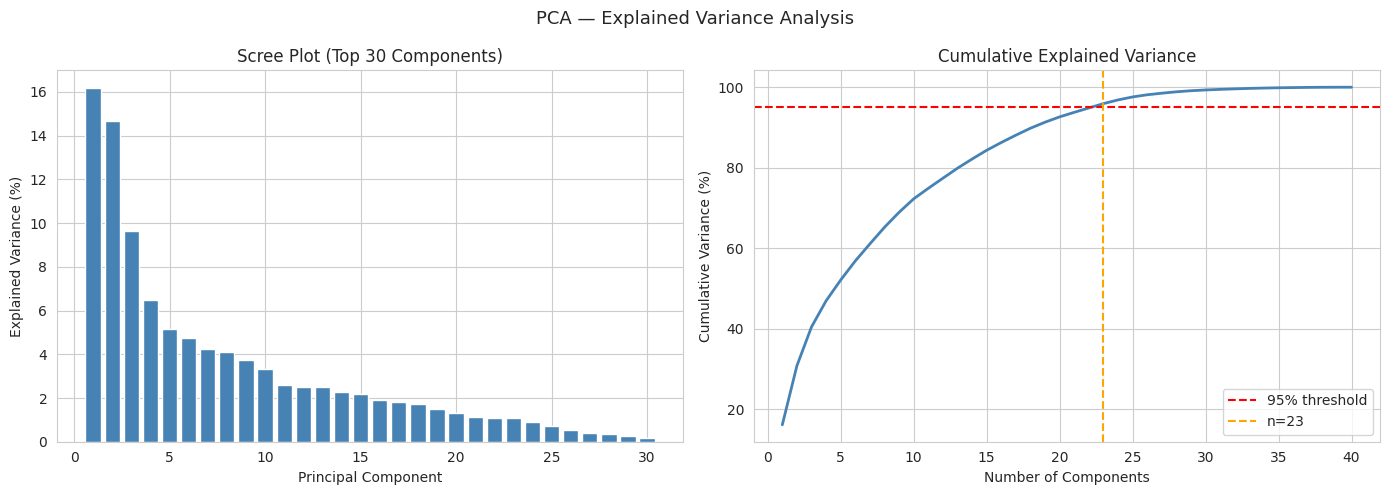


X_train after PCA: (257668, 23)
X_test  after PCA: (42209, 23)
Dimensionality reduced from 40 → 23 features


In [ ]:

pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cumvar >= 0.95) + 1
print(f'Components needed to explain 95% variance: {n_components_95}')
print(f'Total original features: {X_train_scaled.shape[1]}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].bar(
    range(1, min(30, len(pca_full.explained_variance_ratio_)) + 1),
    pca_full.explained_variance_ratio_[:30] * 100,
    color='steelblue', edgecolor='white'
)
axes[0].set_title('Scree Plot (Top 30 Components)')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')


axes[1].plot(range(1, len(cumvar) + 1), cumvar * 100, color='steelblue', linewidth=2)
axes[1].axhline(95, color='red', linestyle='--', label='95% threshold')
axes[1].axvline(n_components_95, color='orange', linestyle='--', label=f'n={n_components_95}')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].legend()

plt.suptitle('PCA — Explained Variance Analysis', fontsize=13)
plt.tight_layout()
plt.show()


pca = PCA(n_components=n_components_95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f'\nX_train after PCA: {X_train_pca.shape}')
print(f'X_test  after PCA: {X_test_pca.shape}')
print(f'Dimensionality reduced from {X_train_scaled.shape[1]} \u2192 {X_train_pca.shape[1]} features')

## Selected PCA Components -- Ranked Importance, Mapped to Original Feature Names

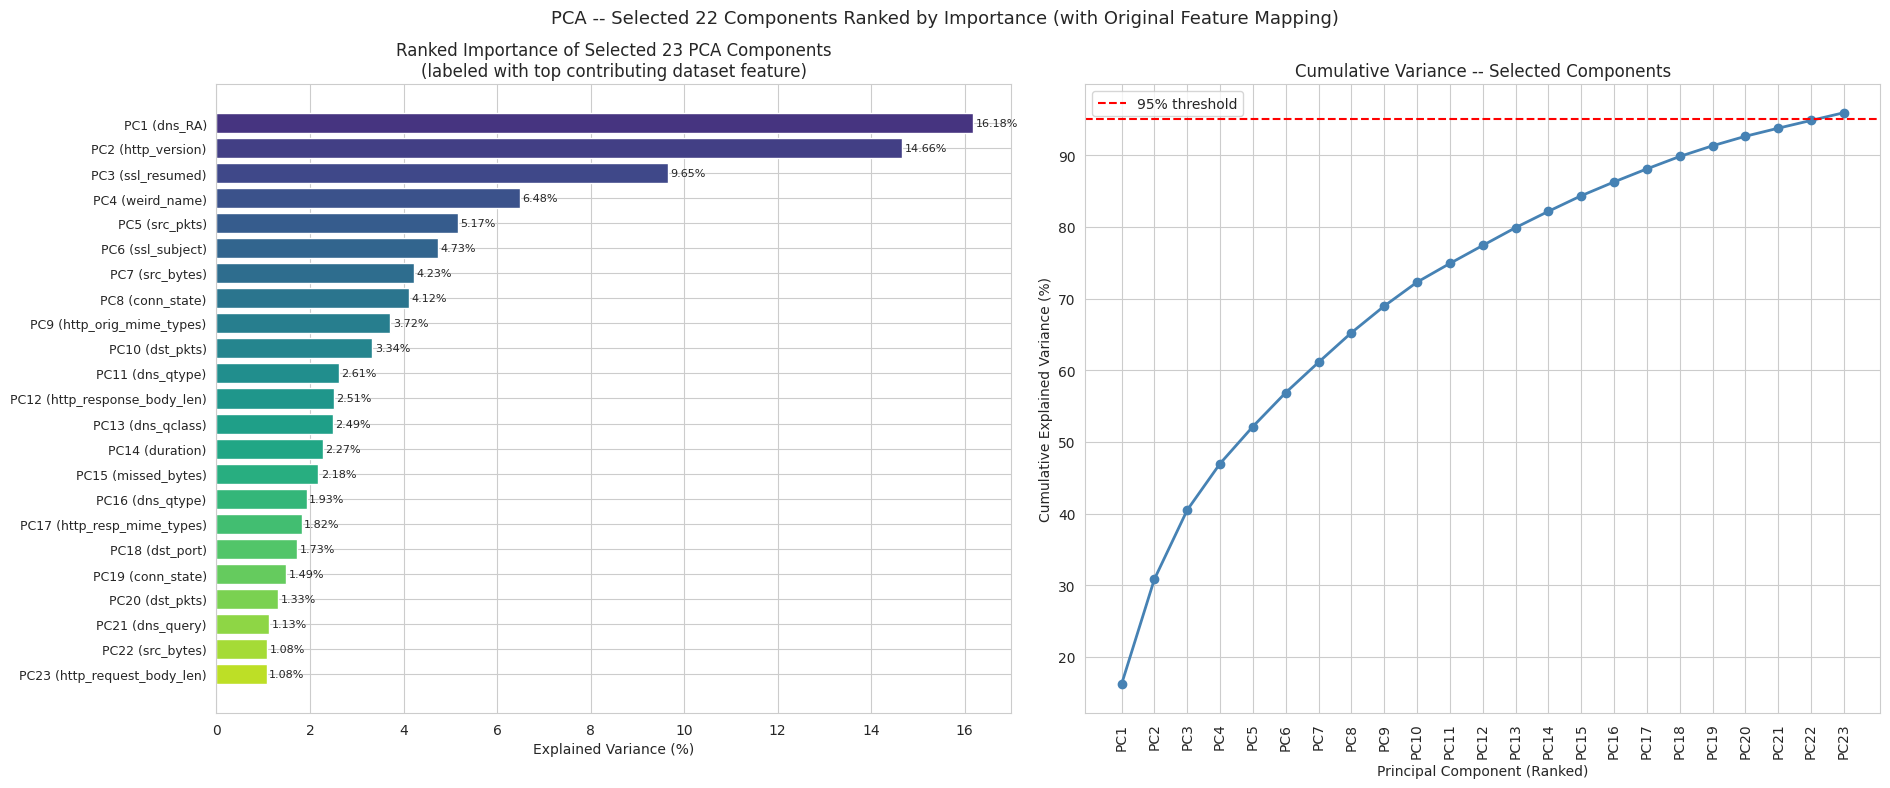

 Rank Component Top Contributing Feature  Loading (weight)  Explained Variance (%)  Cumulative Variance (%)
    1       PC1                   dns_RA            0.3629                  16.182                   16.182
    2       PC2             http_version            0.3840                  14.659                   30.841
    3       PC3              ssl_resumed            0.4988                   9.647                   40.487
    4       PC4               weird_name            0.6105                   6.482                   46.969
    5       PC5                 src_pkts            0.6001                   5.168                   52.137
    6       PC6              ssl_subject            0.6884                   4.734                   56.870
    7       PC7                src_bytes            0.5500                   4.233                   61.103
    8       PC8               conn_state            0.4250                   4.123                   65.227
    9       PC9     http_ori

In [ ]:


feature_names = df.columns.tolist()

importance = pca.explained_variance_ratio_ * 100
component_labels = [f'PC{i+1}' for i in range(len(importance))]


loadings = pca.components_
top_feature_idx = np.argmax(np.abs(loadings), axis=1)
top_feature_names = [feature_names[i] for i in top_feature_idx]
top_feature_loading = [loadings[i, top_feature_idx[i]] for i in range(len(top_feature_idx))]

combined_labels = [f'{component_labels[i]} ({top_feature_names[i]})' for i in range(len(importance))]

rank_order = np.argsort(importance)[::-1]
ranked_importance = importance[rank_order]
ranked_labels = [combined_labels[i] for i in rank_order]
cum_ranked = np.cumsum(ranked_importance)

fig, axes = plt.subplots(1, 2, figsize=(19, 8))

colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(ranked_importance)))
bars = axes[0].barh(range(len(ranked_importance)), ranked_importance[::-1],
                     color=colors[::-1], edgecolor='white')
axes[0].set_yticks(range(len(ranked_labels)))
axes[0].set_yticklabels(ranked_labels[::-1], fontsize=9)
axes[0].set_xlabel('Explained Variance (%)')
axes[0].set_title(f'Ranked Importance of Selected {len(importance)} PCA Components\n(labeled with top contributing dataset feature)')

for bar, val in zip(bars, ranked_importance[::-1]):
    axes[0].text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                 f'{val:.2f}%', va='center', fontsize=8)

axes[1].plot(range(1, len(cum_ranked) + 1), cum_ranked, marker='o',
             color='steelblue', linewidth=2)
axes[1].axhline(95, color='red', linestyle='--', label='95% threshold')
axes[1].set_xticks(range(1, len(cum_ranked) + 1))
axes[1].set_xticklabels([component_labels[i] for i in rank_order], rotation=90)
axes[1].set_xlabel('Principal Component (Ranked)')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Variance -- Selected Components')
axes[1].legend()

plt.suptitle('PCA -- Selected 22 Components Ranked by Importance (with Original Feature Mapping)', fontsize=13)
plt.tight_layout()
plt.show()


pca_importance_df = pd.DataFrame({
    'Rank': range(1, len(ranked_importance) + 1),
    'Component': [component_labels[i] for i in rank_order],
    'Top Contributing Feature': [top_feature_names[i] for i in rank_order],
    'Loading (weight)': [round(top_feature_loading[i], 4) for i in rank_order],
    'Explained Variance (%)': ranked_importance.round(3),
    'Cumulative Variance (%)': cum_ranked.round(3)
})
print(pca_importance_df.to_string(index=False))


## Dropped (Unimportant) Components -- Excluded After PCA, Mapped to Original Feature Names

Total components (original features) : 40
Kept (important)                      : 23
Dropped (unimportant)                 : 17


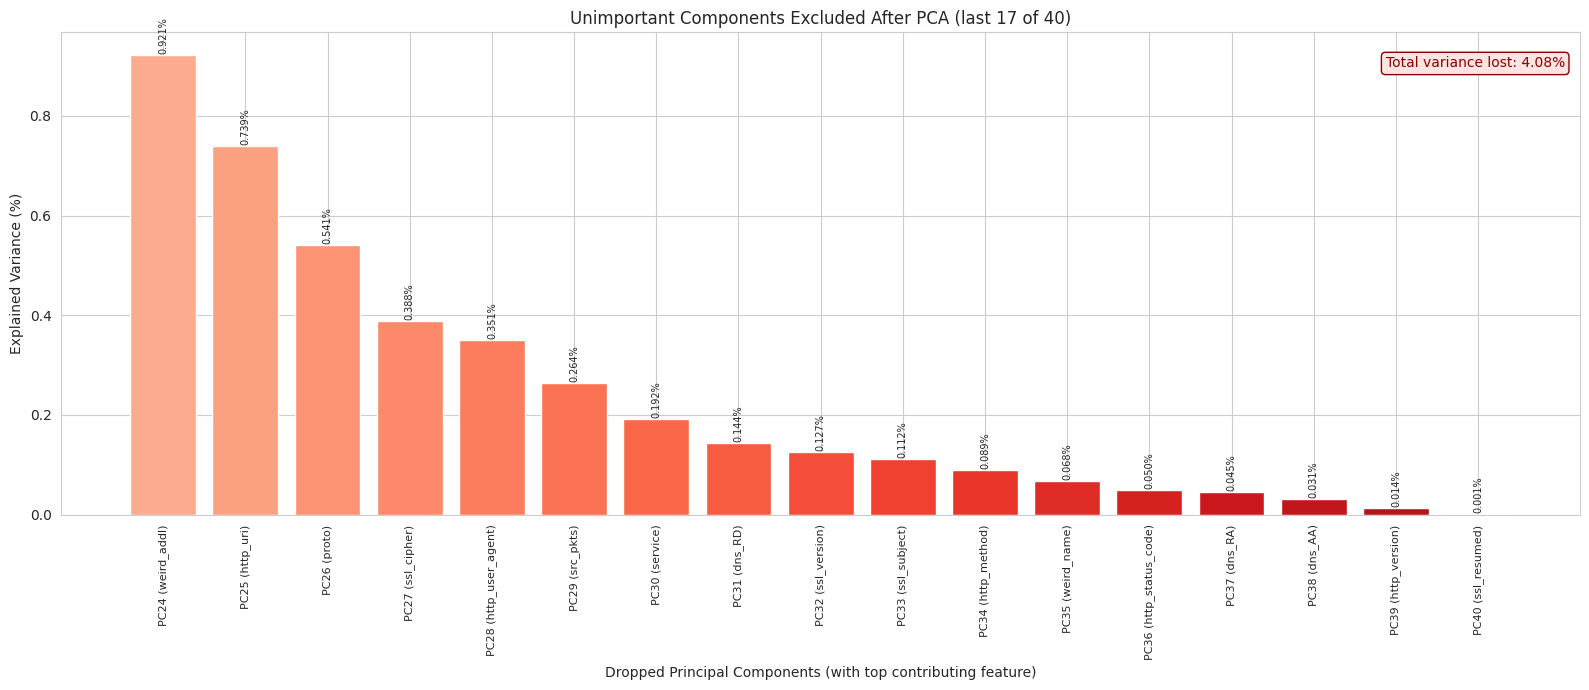

Component Top Contributing Feature  Loading (weight)  Explained Variance (%)
     PC24               weird_addl            0.7518                  0.9213
     PC25                 http_uri            0.7367                  0.7387
     PC26                    proto            0.6586                  0.5406
     PC27               ssl_cipher            0.8302                  0.3877
     PC28          http_user_agent            0.6064                  0.3508
     PC29                 src_pkts            0.6670                  0.2636
     PC30                  service            0.7171                  0.1923
     PC31                   dns_RD            0.7255                  0.1443
     PC32              ssl_version            0.6432                  0.1265
     PC33              ssl_subject            0.7077                  0.1120
     PC34              http_method            0.8867                  0.0892
     PC35               weird_name            0.7831                  0.0679

In [ ]:


feature_names = df.columns.tolist()

total_features = len(pca_full.explained_variance_ratio_)
n_kept = n_components_95
n_dropped = total_features - n_kept

dropped_importance = pca_full.explained_variance_ratio_[n_kept:] * 100
dropped_labels = [f'PC{i+1}' for i in range(n_kept, total_features)]


dropped_loadings = pca_full.components_[n_kept:]
dropped_top_feature_idx = np.argmax(np.abs(dropped_loadings), axis=1)
dropped_top_feature_names = [feature_names[i] for i in dropped_top_feature_idx]
dropped_top_feature_loading = [dropped_loadings[i, dropped_top_feature_idx[i]] for i in range(len(dropped_top_feature_idx))]

dropped_combined_labels = [f'{dropped_labels[i]} ({dropped_top_feature_names[i]})' for i in range(len(dropped_importance))]

print(f'Total components (original features) : {total_features}')
print(f'Kept (important)                      : {n_kept}')
print(f'Dropped (unimportant)                 : {n_dropped}')

fig, ax = plt.subplots(figsize=(16, 7))

colors_dropped = plt.cm.Reds(np.linspace(0.3, 0.85, len(dropped_importance)))
bars = ax.bar(range(len(dropped_importance)), dropped_importance,
              color=colors_dropped, edgecolor='white')

ax.set_xticks(range(len(dropped_combined_labels)))
ax.set_xticklabels(dropped_combined_labels, rotation=90, fontsize=8)
ax.set_xlabel('Dropped Principal Components (with top contributing feature)')
ax.set_ylabel('Explained Variance (%)')
ax.set_title(f'Unimportant Components Excluded After PCA (last {n_dropped} of {total_features})')

for bar, val in zip(bars, dropped_importance):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{val:.3f}%', ha='center', va='bottom', fontsize=7, rotation=90)

total_dropped_variance = dropped_importance.sum()
ax.text(0.99, 0.95, f'Total variance lost: {total_dropped_variance:.2f}%',
        transform=ax.transAxes, ha='right', va='top',
        fontsize=10, color='darkred',
        bbox=dict(boxstyle='round', facecolor='mistyrose', edgecolor='darkred'))

plt.tight_layout()
plt.show()


dropped_df = pd.DataFrame({
    'Component': dropped_labels,
    'Top Contributing Feature': dropped_top_feature_names,
    'Loading (weight)': [round(v, 4) for v in dropped_top_feature_loading],
    'Explained Variance (%)': dropped_importance.round(4)
})
print(dropped_df.to_string(index=False))
print(f'\nTotal variance lost by dropping these {n_dropped} components: {total_dropped_variance:.3f}%')


## Advanced Hybrid Feature Selection — Filter + Embedded + Wrapper + SHAP (Ensemble Rank Aggregation)

**Contribution.** PCA compresses correlated features into components, which loses each feature's original identity/interpretability. This section adds an interpretable, complementary alternative: an **ensemble/hybrid feature selection** pipeline that combines four independent, orthogonal ranking strategies and aggregates them with **Ensemble Rank Aggregation (average-rank fusion)**:

1. **Filter** — Mutual Information between each feature and the target
2. **Embedded** — XGBoost's internal (gain-based) feature importance
3. **Wrapper** — Recursive Feature Elimination (RFE) with an XGBoost estimator
4. **Explainable** — mean |SHAP value| per feature (ties directly into the 'no XAI applied' gap flagged in the related-work table)

No single method is fully trustworthy on its own (each has known biases), so the final ranking is the **average rank across all four**, which is more robust than any individual method and keeps the selected features as real, named columns — unlike PCA's synthetic components.

In [ ]:
# Install SHAP (only extra dependency needed for this section)
!pip install -q shap


In [ ]:
import shap
from sklearn.feature_selection import mutual_info_classif, RFE

feature_names = df.columns.tolist()
X_train_fs_df = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_fs_df  = pd.DataFrame(X_test_scaled, columns=feature_names)

# Subsample for the heavier wrapper/SHAP steps -- keeps this tractable on the
# large SMOTE-resampled training set without changing the final ranking much
FS_SAMPLE_N = min(20000, len(X_train_fs_df))
rng = np.random.RandomState(42)
fs_idx = rng.choice(len(X_train_fs_df), size=FS_SAMPLE_N, replace=False)
X_fs_sample = X_train_fs_df.iloc[fs_idx]
y_fs_sample = y_train[fs_idx]

# 1. Filter -- Mutual Information
mi_scores = mutual_info_classif(X_fs_sample, y_fs_sample, random_state=42)
mi_rank = pd.Series(mi_scores, index=feature_names).rank(ascending=False)

# 2. Embedded -- XGBoost feature importance
xgb_fs = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                        eval_metric='logloss', random_state=42, n_jobs=-1)
xgb_fs.fit(X_fs_sample, y_fs_sample)
imp_rank = pd.Series(xgb_fs.feature_importances_, index=feature_names).rank(ascending=False)

# 3. Wrapper -- Recursive Feature Elimination (XGBoost estimator)
N_SELECT = 20
rfe = RFE(
    estimator=XGBClassifier(n_estimators=80, max_depth=4, eval_metric='logloss',
                             random_state=42, n_jobs=-1),
    n_features_to_select=N_SELECT, step=3
)
rfe.fit(X_fs_sample, y_fs_sample)
rfe_rank = pd.Series(rfe.ranking_, index=feature_names).rank(method='min', ascending=True)

# 4. Explainable -- mean |SHAP value| (sampled instances, all classes averaged)
shap_sample = X_fs_sample.sample(min(2000, len(X_fs_sample)), random_state=42)
explainer = shap.TreeExplainer(xgb_fs)
shap_values = explainer.shap_values(shap_sample)
shap_arr = np.array(shap_values)
mean_abs_shap = shap_arr.mean(axis=(0, 2)) if shap_arr.ndim == 3 else np.abs(shap_arr).mean(axis=0)
mean_abs_shap = np.abs(mean_abs_shap) if shap_arr.ndim == 3 else mean_abs_shap
shap_rank = pd.Series(mean_abs_shap, index=feature_names).rank(ascending=False)

# --- Ensemble Rank Aggregation (average rank across all 4 methods) ---
rank_df = pd.DataFrame({
    'Mutual_Info': mi_rank,
    'XGB_Importance': imp_rank,
    'RFE': rfe_rank,
    'SHAP': shap_rank,
})
rank_df['Avg_Rank'] = rank_df.mean(axis=1)
final_ranking = rank_df.sort_values('Avg_Rank')
print(final_ranking.head(N_SELECT))

selected_features = final_ranking.index[:N_SELECT].tolist()
print(f'\nTop-{N_SELECT} selected features (hybrid ranking):')
print(selected_features)


                  Mutual_Info  XGB_Importance  RFE  SHAP  Avg_Rank
dst_port                  2.0             2.0  1.0   2.0      1.75
src_port                  5.0             4.0  1.0   3.0      3.25
proto                    11.0             1.0  1.0   1.0      3.50
src_pkts                  6.0             9.0  1.0   4.0      5.00
conn_state                4.0             8.0  1.0   9.0      5.50
dst_ip_bytes              3.0            11.0  1.0   8.0      5.75
dns_query                 7.0             5.0  1.0  10.0      5.75
dns_rejected             12.0             6.0  1.0  11.0      7.50
src_ip_bytes              1.0            25.0  1.0   6.0      8.25
duration                  9.0            26.0  1.0   5.0     10.25
service                  10.0            16.0  1.0  16.0     10.75
dns_qtype                16.0            14.0  1.0  12.0     10.75
src_bytes                 8.0            18.0  1.0  17.0     11.00
dst_pkts                 13.0            24.0  1.0   7.0     1

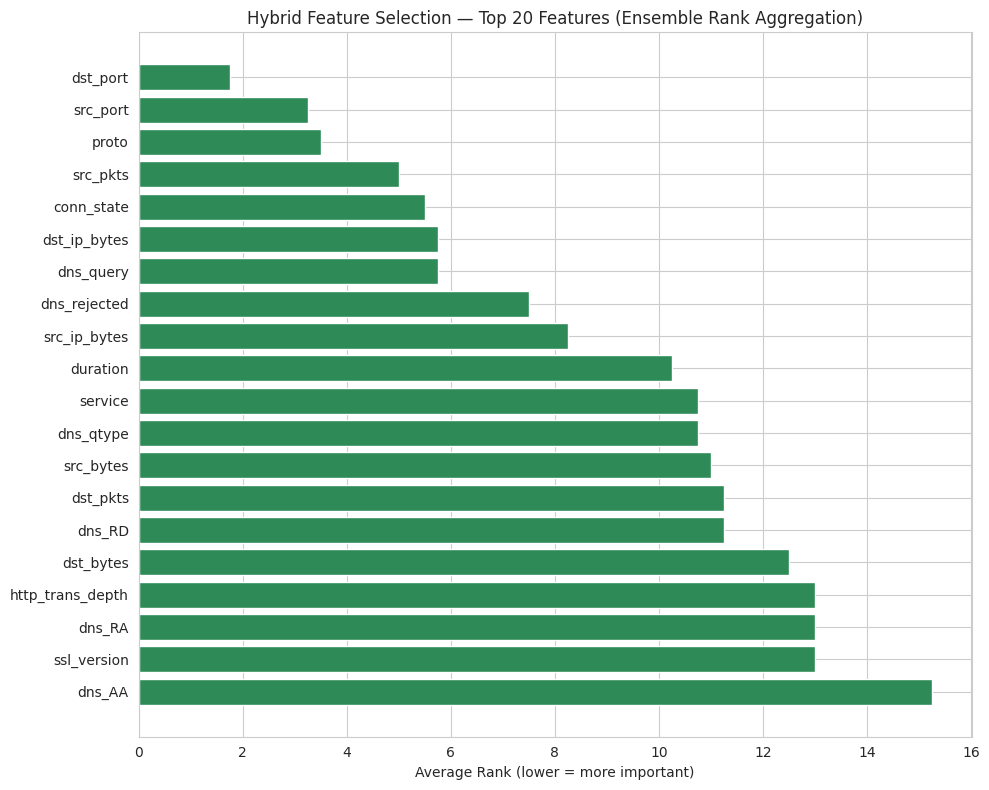

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
plot_df = final_ranking.head(N_SELECT).iloc[::-1]
ax.barh(plot_df.index, plot_df['Avg_Rank'], color='seagreen')
ax.set_xlabel('Average Rank (lower = more important)')
ax.set_title(f'Hybrid Feature Selection — Top {N_SELECT} Features (Ensemble Rank Aggregation)')
plt.tight_layout()
plt.show()


In [ ]:
X_train_fs = X_train_fs_df[selected_features].values
X_test_fs  = X_test_fs_df[selected_features].values
print('X_train_fs:', X_train_fs.shape, ' X_test_fs:', X_test_fs.shape)


X_train_fs: (257668, 20)  X_test_fs: (42209, 20)


### PCA vs Hybrid Feature Selection — Quick Benchmark

A fixed XGBoost probe trained once on the PCA components and once on the hybrid-selected features, to show the selected feature set is competitive (or better) while staying fully interpretable.

XGBoost on PCA (23 components):     accuracy = 0.9976
XGBoost on Hybrid FS (20 features):  accuracy = 0.9990


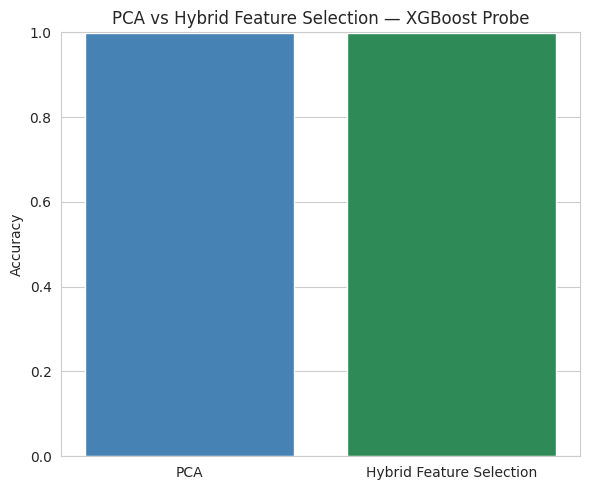


Note: X_train_fs / X_test_fs are available as a drop-in alternative to X_train_pca / X_test_pca for any model below, if you want to report results on the interpretable feature-selected set instead of (or alongside) PCA.


In [ ]:
probe_pca = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                           eval_metric='logloss', random_state=42, n_jobs=-1)
probe_pca.fit(X_train_pca, y_train)
acc_pca = accuracy_score(y_test, probe_pca.predict(X_test_pca))

probe_fs = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                          eval_metric='logloss', random_state=42, n_jobs=-1)
probe_fs.fit(X_train_fs, y_train)
acc_fs = accuracy_score(y_test, probe_fs.predict(X_test_fs))

print(f'XGBoost on PCA ({X_train_pca.shape[1]} components):     accuracy = {acc_pca:.4f}')
print(f'XGBoost on Hybrid FS ({X_train_fs.shape[1]} features):  accuracy = {acc_fs:.4f}')

plt.figure(figsize=(6, 5))
plt.bar(['PCA', 'Hybrid Feature Selection'], [acc_pca, acc_fs], color=['steelblue', 'seagreen'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('PCA vs Hybrid Feature Selection — XGBoost Probe')
plt.tight_layout()
plt.show()

print('\nNote: X_train_fs / X_test_fs are available as a drop-in alternative to X_train_pca / '
      'X_test_pca for any model below, if you want to report results on the interpretable '
      'feature-selected set instead of (or alongside) PCA.')


## Model Evaluation Function

In [ ]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, class_names):
    """Train model, print classification report + ROC-AUC/PR-AUC (binary),
    and plot confusion matrix."""
    print('=' * 70)
    print(f'MODEL: {name}')
    print('=' * 70)

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    acc = accuracy_score(y_te, y_pred)
    print(f'Accuracy: {acc:.4f}')

    # Binary task -- also report ROC-AUC / PR-AUC using 'Attack' as the positive class
    if len(class_names) == 2 and hasattr(model, 'predict_proba'):
        pos_idx = list(class_names).index('Attack') if 'Attack' in class_names else 1
        y_proba = model.predict_proba(X_te)[:, pos_idx]
        y_te_bin = (y_te == pos_idx).astype(int)
        roc_auc = roc_auc_score(y_te_bin, y_proba)
        pr_auc = average_precision_score(y_te_bin, y_proba)
        print(f'ROC-AUC: {roc_auc:.4f}   PR-AUC: {pr_auc:.4f}')
    print()

    print('Classification Report:')
    print(classification_report(y_te, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_te, y_pred)
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
        ax=ax, cmap='Blues', xticks_rotation=45, values_format='d'
    )
    ax.grid(False)
    ax.set_title(f'Confusion Matrix — {name}\nAccuracy: {acc:.4f}')
    plt.tight_layout()
    plt.show()

    return acc


## Random Forest


MODEL: Random Forest (PCA)
Accuracy: 0.9980
ROC-AUC: 0.9997   PR-AUC: 0.9998

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       1.00      1.00      1.00     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



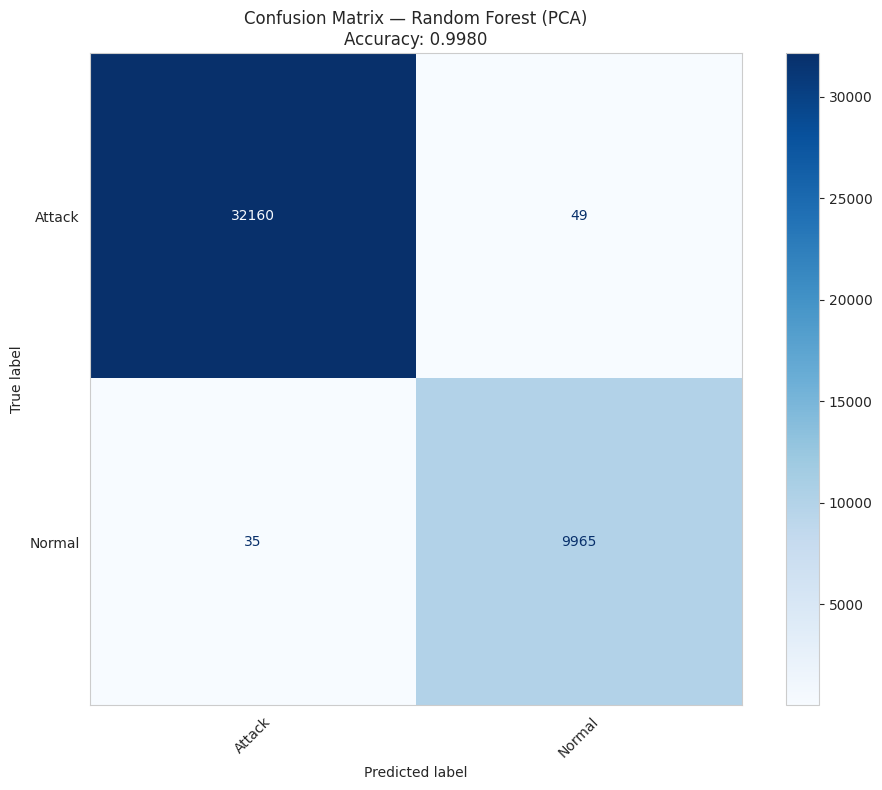

MODEL: Random Forest (Hybrid FS)
Accuracy: 0.9991
ROC-AUC: 0.9999   PR-AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       1.00      1.00      1.00     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



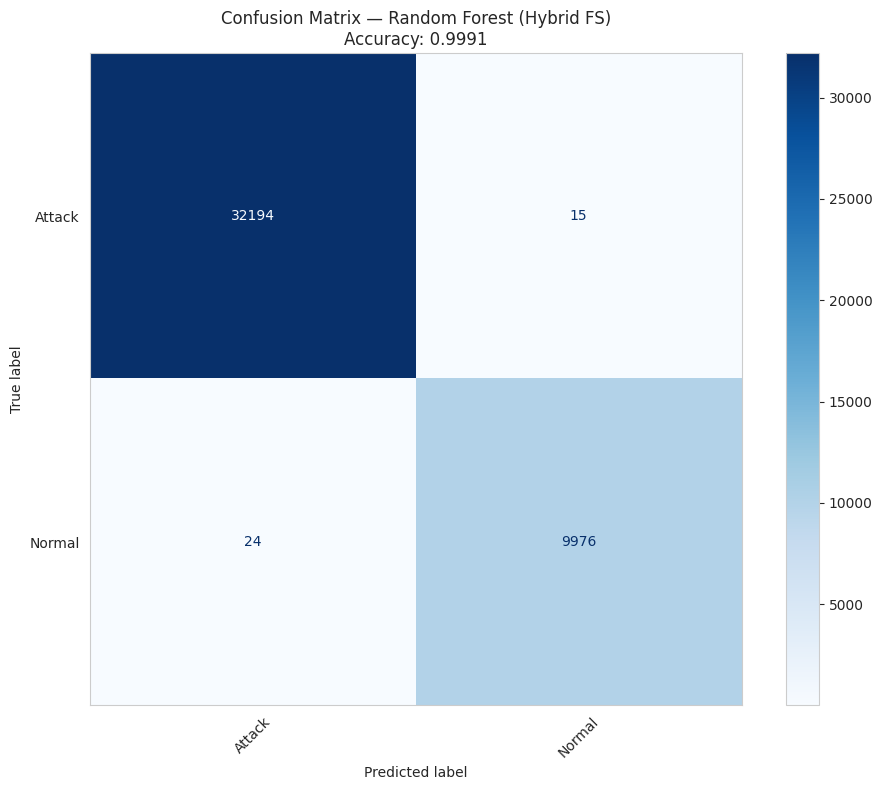

In [ ]:
rf_pca = RandomForestClassifier(
    n_estimators=50,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_acc_pca = evaluate_model('Random Forest (PCA)', rf_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)

rf_fs = RandomForestClassifier(
    n_estimators=50,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_acc_fs = evaluate_model('Random Forest (Hybrid FS)', rf_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)


## K-Nearest Neighbors (KNN)


MODEL: KNN (PCA)
Accuracy: 0.9975
ROC-AUC: 0.9987   PR-AUC: 0.9992

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      1.00      0.99     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



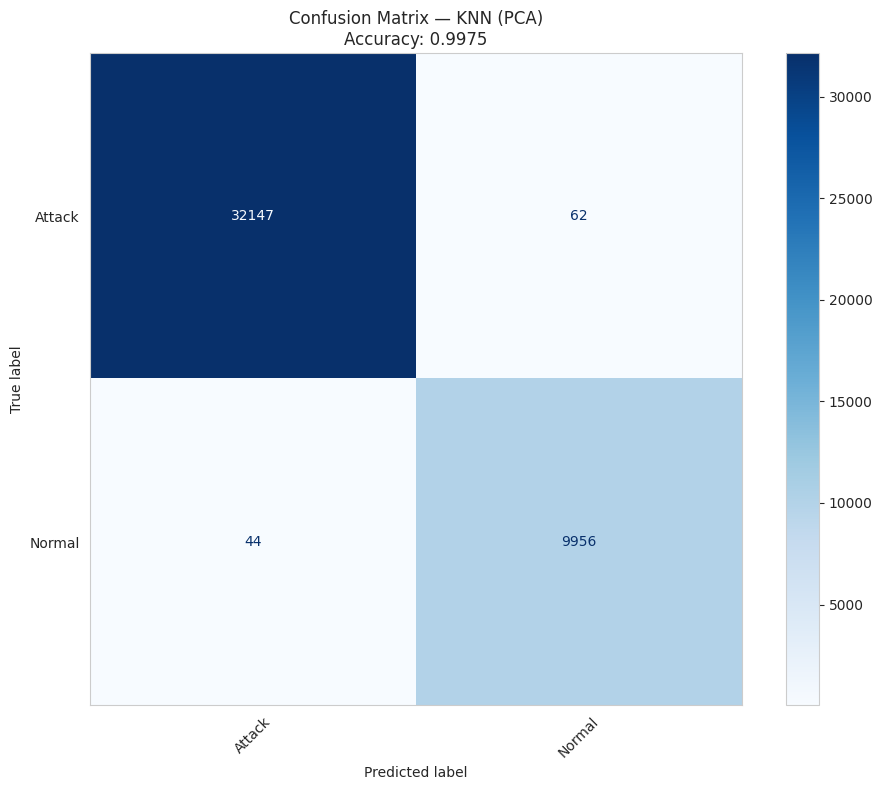

MODEL: KNN (Hybrid FS)
Accuracy: 0.9975
ROC-AUC: 0.9986   PR-AUC: 0.9991

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



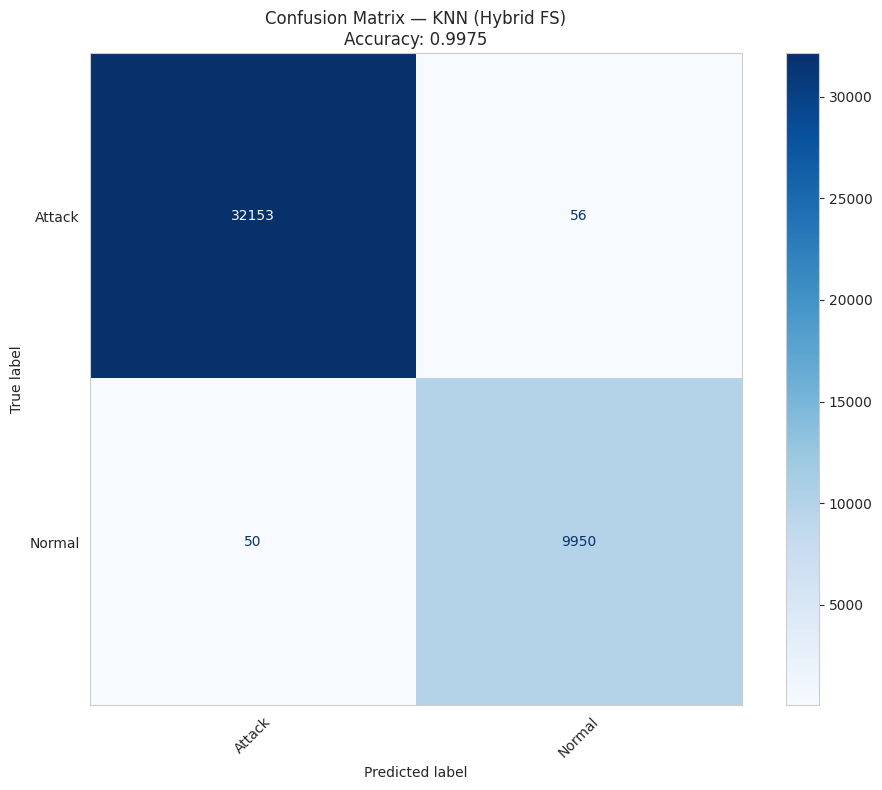

In [ ]:
knn_pca = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_acc_pca = evaluate_model('KNN (PCA)', knn_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)

knn_fs = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_acc_fs = evaluate_model('KNN (Hybrid FS)', knn_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)


## XGBoost


MODEL: XGBoost (PCA)
Accuracy: 0.9969
ROC-AUC: 0.9998   PR-AUC: 0.9999

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      1.00      0.99     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



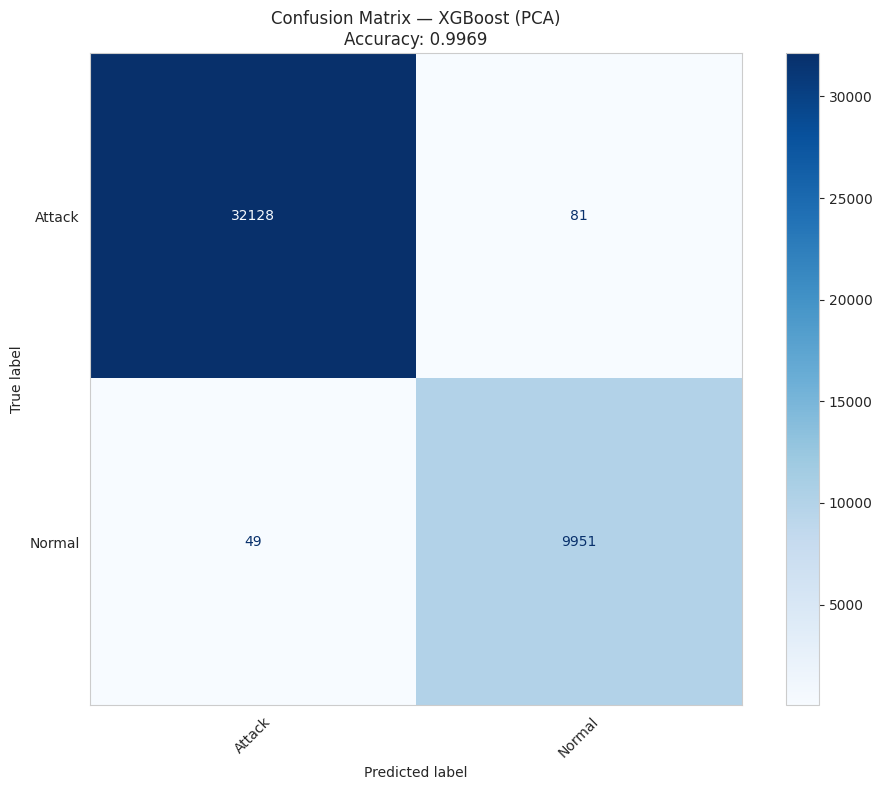

MODEL: XGBoost (Hybrid FS)
Accuracy: 0.9987
ROC-AUC: 1.0000   PR-AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       1.00      1.00      1.00     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



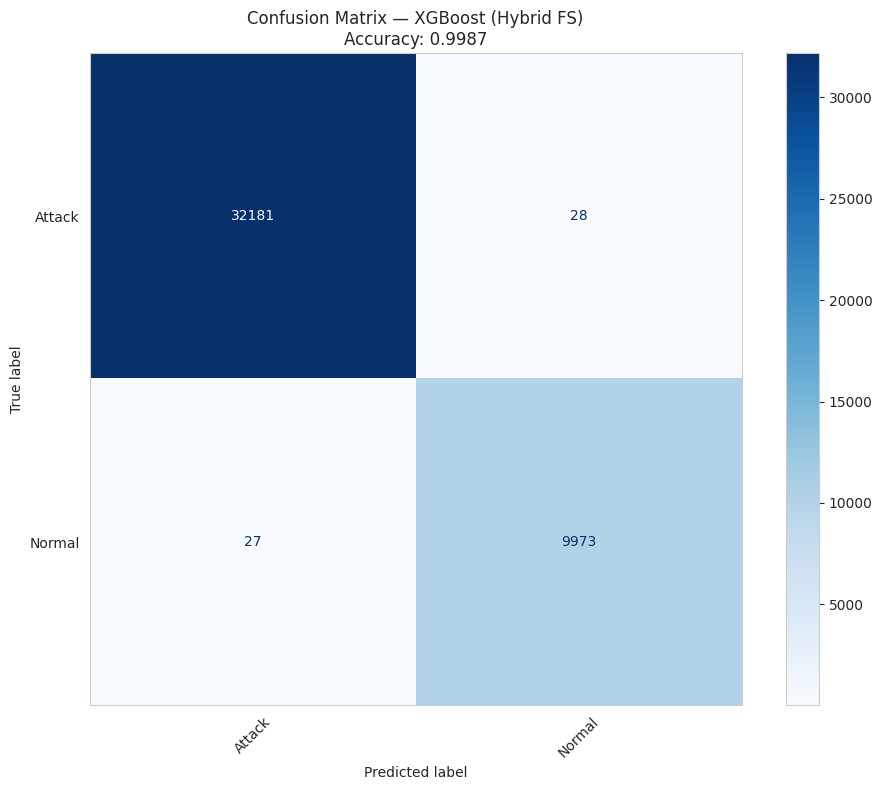

In [ ]:
xgb_pca = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_acc_pca = evaluate_model('XGBoost (PCA)', xgb_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)

xgb_fs = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_acc_fs = evaluate_model('XGBoost (Hybrid FS)', xgb_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)


## CatBoost


MODEL: CatBoost (PCA)
Accuracy: 0.9968
ROC-AUC: 0.9997   PR-AUC: 0.9999

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



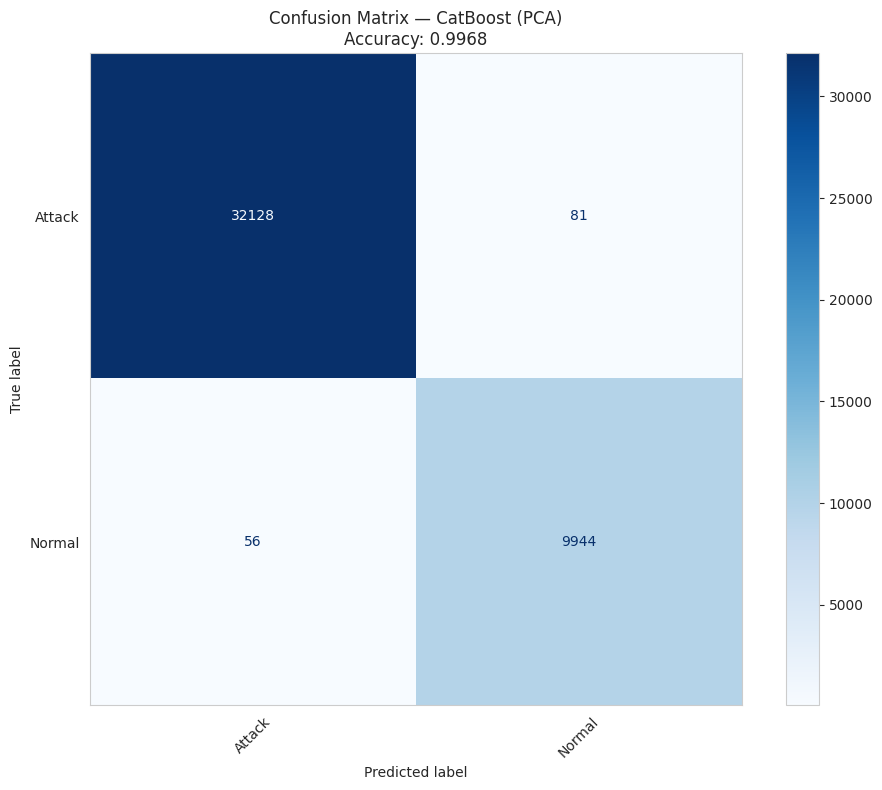

MODEL: CatBoost (Hybrid FS)
Accuracy: 0.9984
ROC-AUC: 0.9999   PR-AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       1.00      1.00      1.00     10000

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



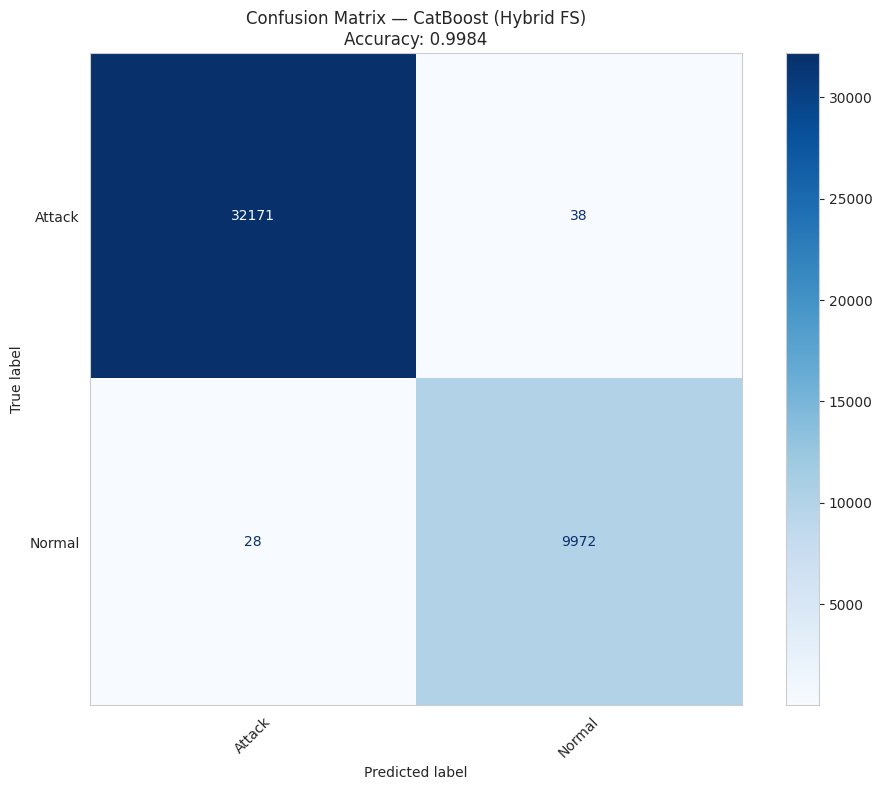

In [ ]:
cat_pca = CatBoostClassifier(
    iterations=200,
    learning_rate=0.1,
    depth=6,
    verbose=0,
    random_state=42
)
cat_acc_pca = evaluate_model('CatBoost (PCA)', cat_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)

cat_fs = CatBoostClassifier(
    iterations=200,
    learning_rate=0.1,
    depth=6,
    verbose=0,
    random_state=42
)
cat_acc_fs = evaluate_model('CatBoost (Hybrid FS)', cat_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)


## Advanced Tabular Deep Learning Models



In [ ]:
# Install dependencies for the deep tabular models below
!pip install -q "tab-transformer-pytorch==0.4.2"
!pip install -q pytorch-tabnet

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.2 MB/s eta 0:00:00
Using device: cuda


In [ ]:
def plot_train_val_curves(history, model_name):
    """Plots side-by-side Loss and Accuracy curves from a
    {'train_loss': [...], 'val_loss': [...], 'train_acc': [...], 'val_acc': [...]} history dict."""
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='steelblue')
    axes[0].plot(epochs_range, history['val_loss'], label='Val Loss', color='indianred')
    axes[0].set_title(f'{model_name} — Loss Curve')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(epochs_range, history['train_acc'], label='Train Accuracy', color='steelblue')
    axes[1].plot(epochs_range, history['val_acc'], label='Val Accuracy', color='indianred')
    axes[1].set_title(f'{model_name} — Accuracy Curve')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    plt.suptitle(f'{model_name} — Training vs Validation', fontsize=13)
    plt.tight_layout()
    plt.show()


# TabTransformer

MODEL: TabTransformer (PCA)
  Epoch 1/30 - train_loss: 0.1121, train_acc: 0.9629, val_loss: 0.0606, val_acc: 0.9779
  Epoch 5/30 - train_loss: 0.0250, train_acc: 0.9928, val_loss: 0.0216, val_acc: 0.9934
  Epoch 10/30 - train_loss: 0.0183, train_acc: 0.9940, val_loss: 0.0165, val_acc: 0.9947
  Epoch 15/30 - train_loss: 0.0164, train_acc: 0.9945, val_loss: 0.0145, val_acc: 0.9955
  Epoch 20/30 - train_loss: 0.0146, train_acc: 0.9951, val_loss: 0.0175, val_acc: 0.9951
  Epoch 25/30 - train_loss: 0.0142, train_acc: 0.9953, val_loss: 0.0127, val_acc: 0.9958
  Epoch 30/30 - train_loss: 0.0133, train_acc: 0.9954, val_loss: 0.0137, val_acc: 0.9960
Accuracy: 0.9954
ROC-AUC: 0.9996   PR-AUC: 0.9998

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           1.00     42209
   macro avg       0.99      0.99      0.99     42209
weigh

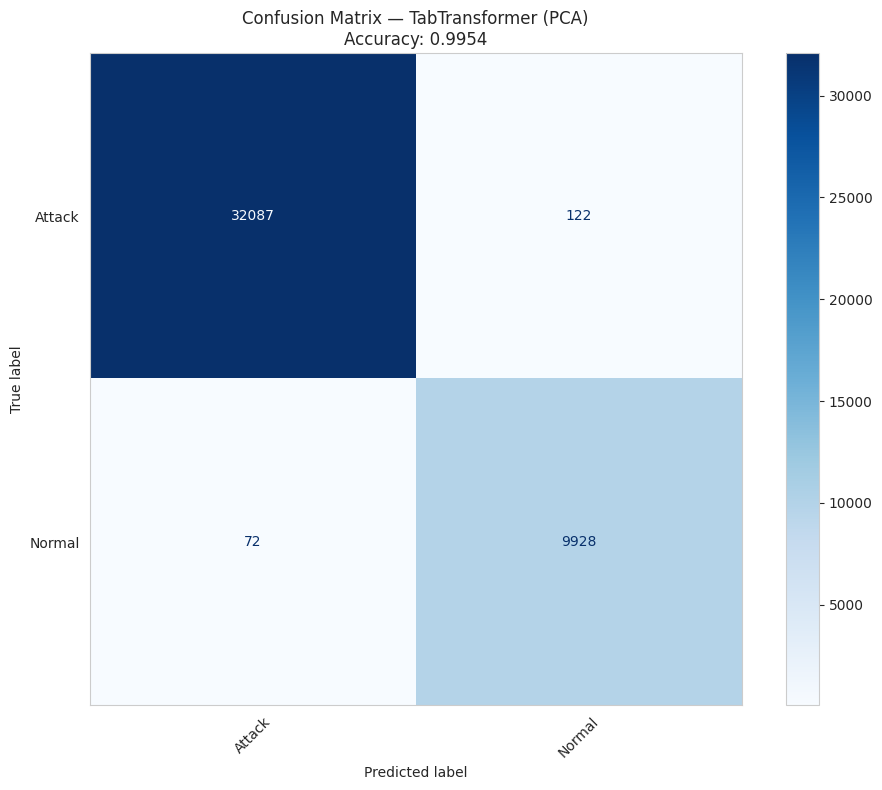

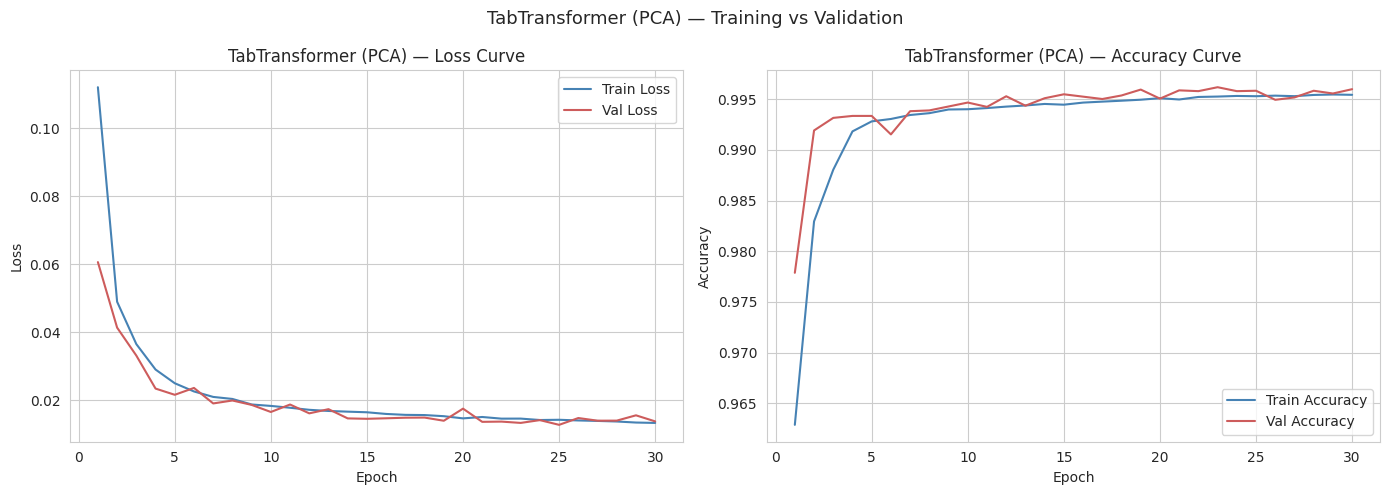

MODEL: TabTransformer (Hybrid FS)
  Epoch 1/30 - train_loss: 0.1100, train_acc: 0.9652, val_loss: 0.0600, val_acc: 0.9802
  Epoch 5/30 - train_loss: 0.0312, train_acc: 0.9911, val_loss: 0.0280, val_acc: 0.9938
  Epoch 10/30 - train_loss: 0.0209, train_acc: 0.9939, val_loss: 0.0194, val_acc: 0.9951
  Epoch 15/30 - train_loss: 0.0182, train_acc: 0.9945, val_loss: 0.0185, val_acc: 0.9945
  Epoch 20/30 - train_loss: 0.0175, train_acc: 0.9947, val_loss: 0.0160, val_acc: 0.9954
  Epoch 25/30 - train_loss: 0.0162, train_acc: 0.9949, val_loss: 0.0157, val_acc: 0.9949
  Epoch 30/30 - train_loss: 0.0155, train_acc: 0.9952, val_loss: 0.0153, val_acc: 0.9954
Accuracy: 0.9952
ROC-AUC: 0.9995   PR-AUC: 0.9997

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           1.00     42209
   macro avg       0.99      0.99      0.99     42209

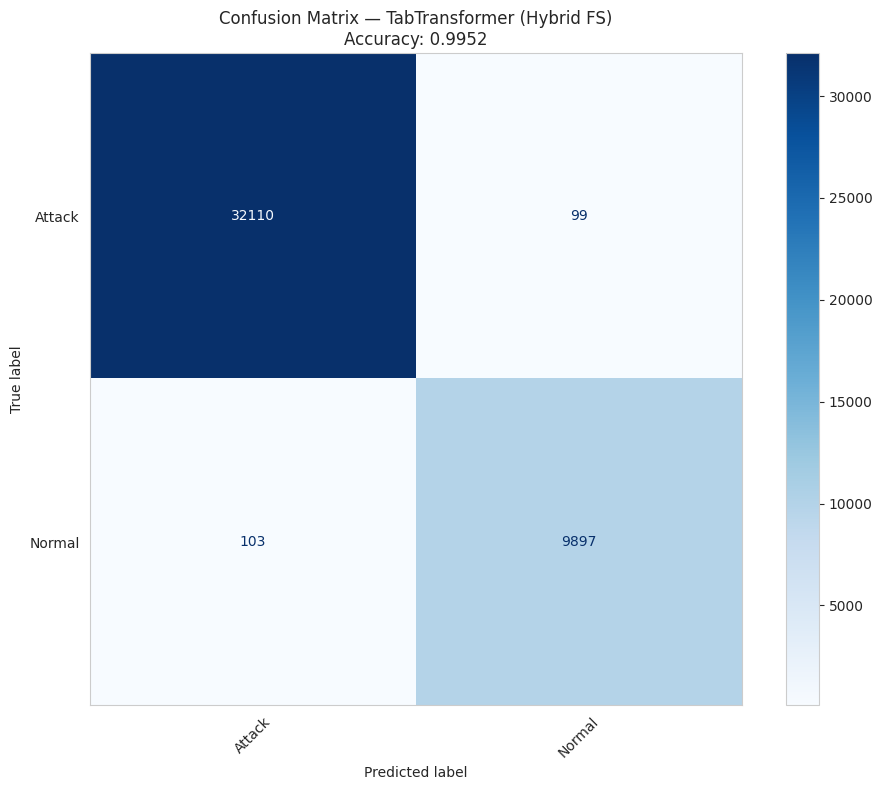

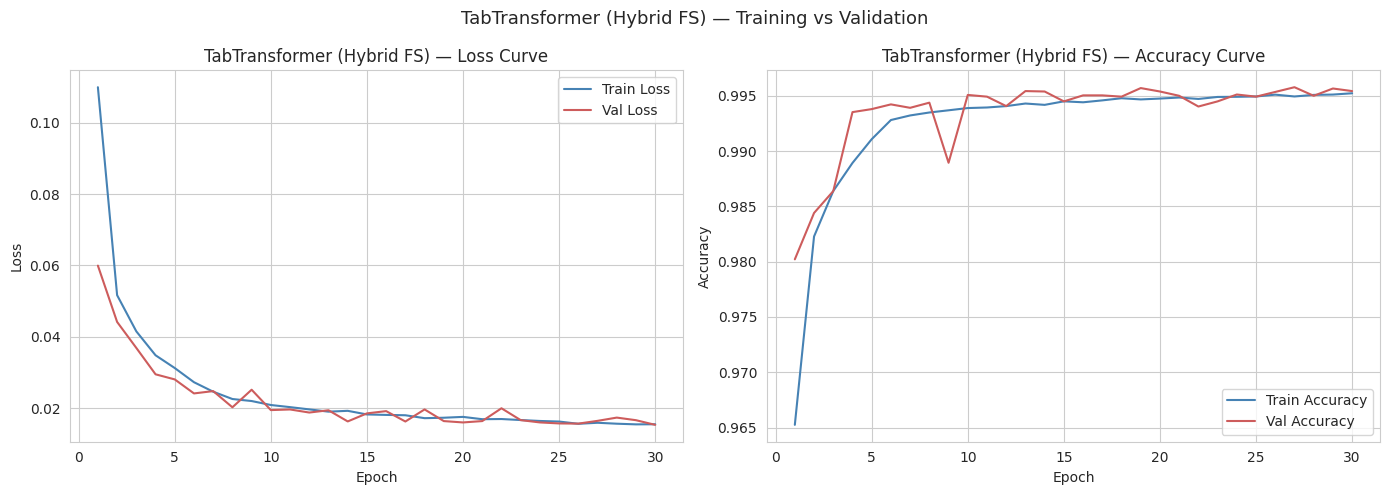

In [ ]:
from tab_transformer_pytorch import TabTransformer

class TabTransformerWrapper:
    """Wraps tab_transformer_pytorch.TabTransformer (a raw nn.Module) in a
    fit/predict interface. Features here are PCA components (all continuous),
    so the categorical branch is left empty. 10%% of the incoming training
    data is held out as a validation split for loss/accuracy curves."""
    def __init__(self, n_features, n_classes, dim=32, depth=4, heads=8,
                 epochs=30, batch_size=256, lr=1e-3, val_size=0.10,
                 device='cpu', random_state=42):
        self.device = device
        self.net = TabTransformer(
            categories=(),
            num_continuous=n_features,
            dim=dim, depth=depth, heads=heads,
            dim_out=n_classes,
            mlp_hidden_mults=(4, 2),
        ).to(device)
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.val_size = val_size
        self.random_state = random_state
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    def _forward(self, X):
        X_t = torch.tensor(X, dtype=torch.float32).to(self.device)
        x_categ = torch.empty((X_t.shape[0], 0), dtype=torch.long).to(self.device)
        return self.net(x_categ, X_t)

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_size, random_state=self.random_state, stratify=y
        )
        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(self.device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(self.device)
        x_categ_tr = torch.empty((X_tr_t.shape[0], 0), dtype=torch.long).to(self.device)

        opt = optim.Adam(self.net.parameters(), lr=self.lr)
        loss_fn = nn.CrossEntropyLoss()
        n = X_tr_t.shape[0]

        for epoch in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n)
            running_loss, correct = 0.0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                logits = self.net(x_categ_tr[idx], X_tr_t[idx])
                loss = loss_fn(logits, y_tr_t[idx])
                loss.backward()
                opt.step()
                running_loss += loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == y_tr_t[idx]).sum().item()
            train_loss = running_loss / n
            train_acc = correct / n

            self.net.eval()
            with torch.no_grad():
                val_logits = self._forward(X_val)
                val_loss = loss_fn(val_logits, y_val_t).item()
                val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()

            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            self.history['train_acc'].append(train_acc)
            self.history['val_acc'].append(val_acc)

            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f'  Epoch {epoch + 1}/{self.epochs} - '
                      f'train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, '
                      f'val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            return torch.softmax(self._forward(X), dim=1).cpu().numpy()

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

tabtransformer_model_pca = TabTransformerWrapper(
    n_features=X_train_pca.shape[1], n_classes=len(class_names), device=device
)
tabtransformer_acc_pca = evaluate_model('TabTransformer (PCA)', tabtransformer_model_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)
plot_train_val_curves(tabtransformer_model_pca.history, 'TabTransformer (PCA)')

tabtransformer_model_fs = TabTransformerWrapper(
    n_features=X_train_fs.shape[1], n_classes=len(class_names), device=device
)
tabtransformer_acc_fs = evaluate_model('TabTransformer (Hybrid FS)', tabtransformer_model_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)
plot_train_val_curves(tabtransformer_model_fs.history, 'TabTransformer (Hybrid FS)')


# Autoencoder-Based Classifier


MODEL: Autoencoder Classifier (PCA)
  Epoch 1/30 - train_loss: 0.1424, train_acc: 0.9551, val_loss: 0.0692, val_acc: 0.9788
  Epoch 5/30 - train_loss: 0.0294, train_acc: 0.9924, val_loss: 0.0230, val_acc: 0.9930
  Epoch 10/30 - train_loss: 0.0221, train_acc: 0.9931, val_loss: 0.0216, val_acc: 0.9939
  Epoch 15/30 - train_loss: 0.0227, train_acc: 0.9931, val_loss: 0.0179, val_acc: 0.9945
  Epoch 20/30 - train_loss: 0.0179, train_acc: 0.9942, val_loss: 0.0171, val_acc: 0.9949
  Epoch 25/30 - train_loss: 0.0165, train_acc: 0.9947, val_loss: 0.0168, val_acc: 0.9954
  Epoch 30/30 - train_loss: 0.0154, train_acc: 0.9950, val_loss: 0.0155, val_acc: 0.9947
Accuracy: 0.9951
ROC-AUC: 0.9996   PR-AUC: 0.9998

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           1.00     42209
   macro avg       0.99      0.99      0.99     422

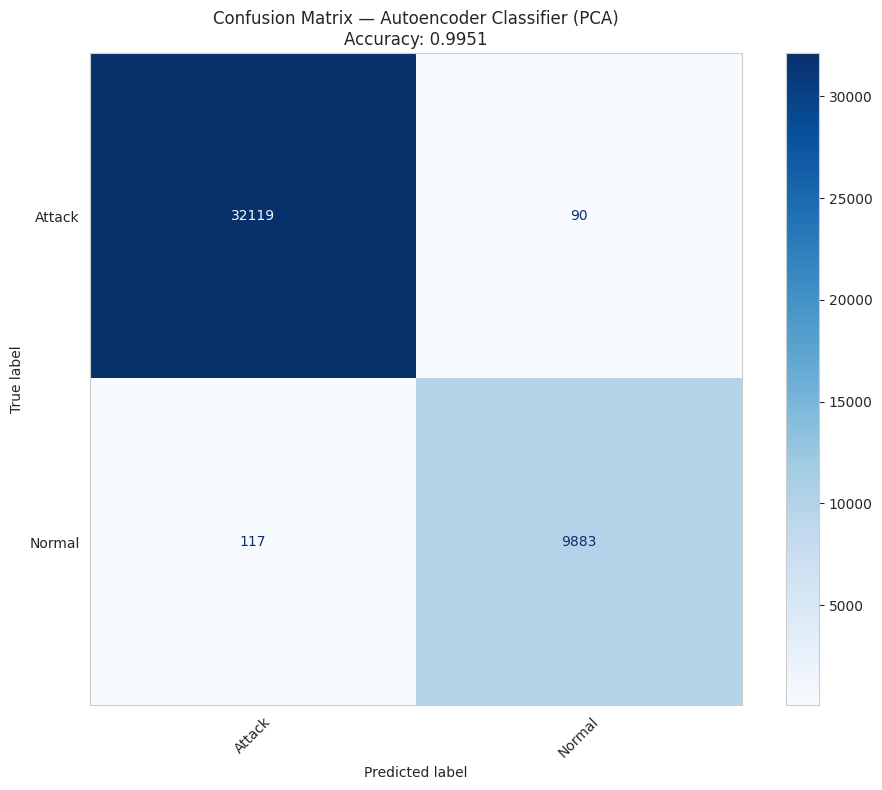

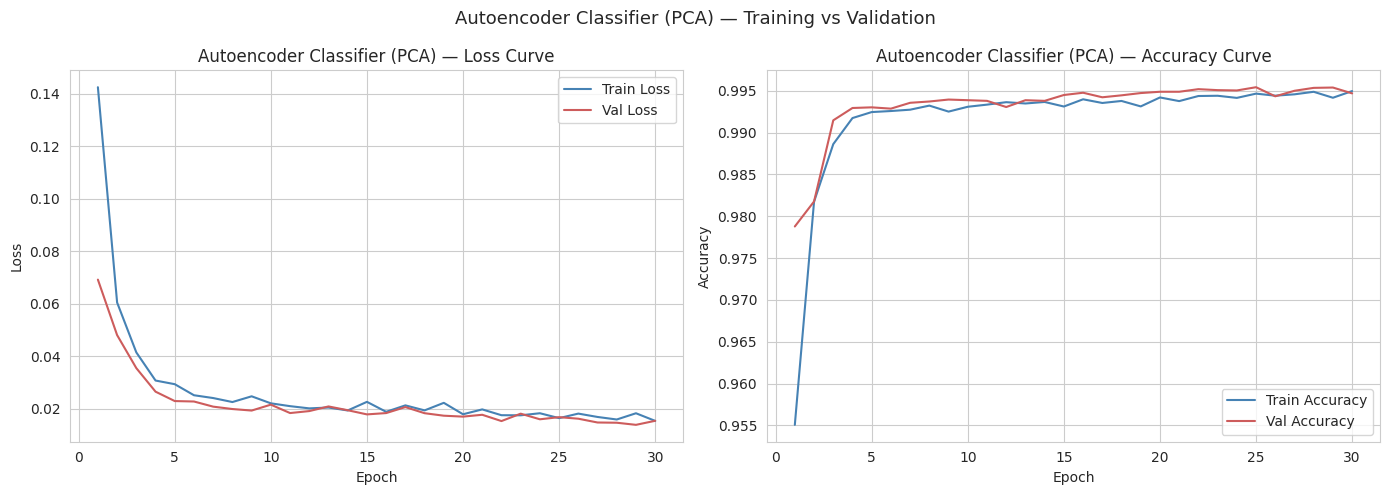

MODEL: Autoencoder Classifier (Hybrid FS)
  Epoch 1/30 - train_loss: 0.1254, train_acc: 0.9619, val_loss: 0.0649, val_acc: 0.9788
  Epoch 5/30 - train_loss: 0.0267, train_acc: 0.9925, val_loss: 0.0240, val_acc: 0.9932
  Epoch 10/30 - train_loss: 0.0229, train_acc: 0.9932, val_loss: 0.0204, val_acc: 0.9939
  Epoch 15/30 - train_loss: 0.0227, train_acc: 0.9933, val_loss: 0.0215, val_acc: 0.9942
  Epoch 20/30 - train_loss: 0.0187, train_acc: 0.9942, val_loss: 0.0193, val_acc: 0.9944
  Epoch 25/30 - train_loss: 0.0175, train_acc: 0.9944, val_loss: 0.0167, val_acc: 0.9948
  Epoch 30/30 - train_loss: 0.0165, train_acc: 0.9947, val_loss: 0.0164, val_acc: 0.9953
Accuracy: 0.9948
ROC-AUC: 0.9995   PR-AUC: 0.9998

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           0.99     42209
   macro avg       0.99      0.99      0.99  

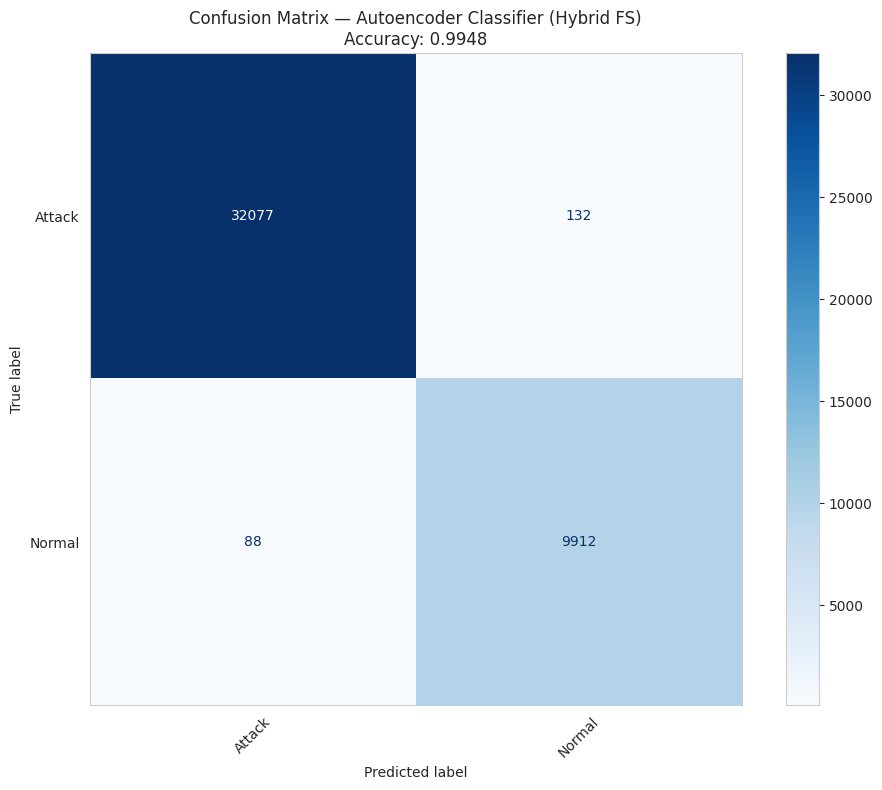

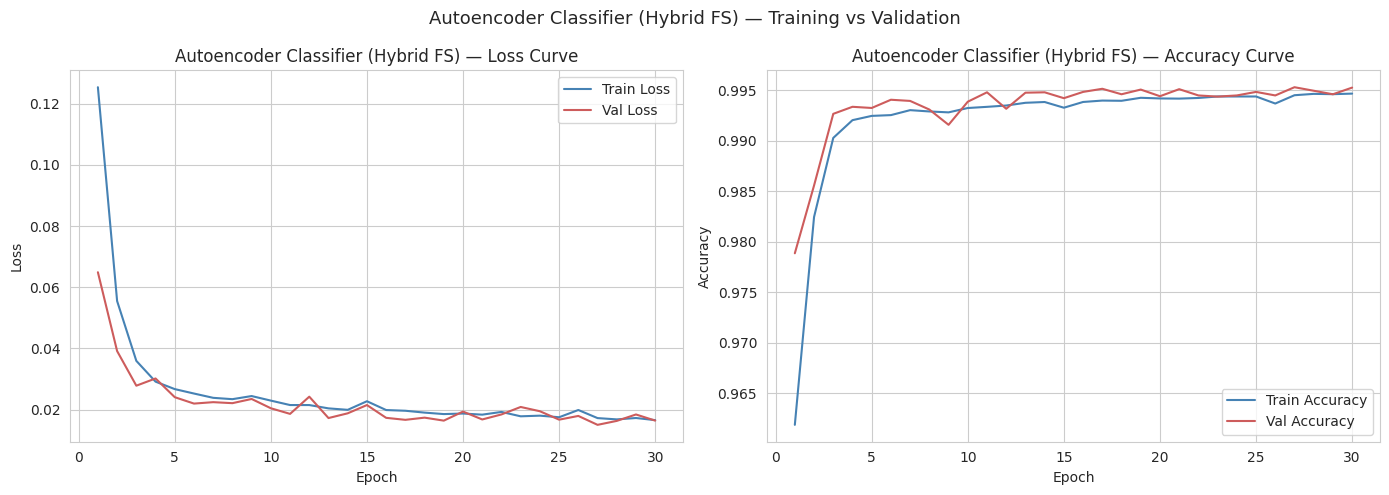

In [ ]:
class AEClassifierNet(nn.Module):
    def __init__(self, n_features, n_classes, latent_dim=32, hidden_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, n_features),
        )
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden_dim, n_classes),
        )

    def forward(self, x):
        z = self.encoder(x)
        recon = self.decoder(z)
        logits = self.classifier(z)
        return logits, recon


class AutoencoderClassifierWrapper:
    """fit/predict adapter around AEClassifierNet, with a 10%% validation split
    and per-epoch train/val classification loss + accuracy tracked in self.history
    (the reconstruction term is used for backprop but kept out of the plotted
    curves so they stay directly comparable to the other models)."""
    def __init__(self, n_features, n_classes, latent_dim=32, hidden_dim=64,
                 epochs=30, batch_size=256, lr=1e-3, val_size=0.10,
                 recon_weight=0.3, device='cpu', random_state=42):
        self.device = device
        self.net = AEClassifierNet(n_features, n_classes, latent_dim, hidden_dim).to(device)
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.val_size = val_size
        self.recon_weight = recon_weight
        self.random_state = random_state
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_size, random_state=self.random_state, stratify=y
        )
        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(self.device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(self.device)
        X_val_t = torch.tensor(X_val, dtype=torch.float32).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(self.device)

        opt = optim.Adam(self.net.parameters(), lr=self.lr)
        ce = nn.CrossEntropyLoss()
        mse = nn.MSELoss()
        n = X_tr_t.shape[0]

        for epoch in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n)
            running_clf_loss, correct = 0.0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                logits, recon = self.net(X_tr_t[idx])
                clf_loss = ce(logits, y_tr_t[idx])
                recon_loss = mse(recon, X_tr_t[idx])
                loss = clf_loss + self.recon_weight * recon_loss
                loss.backward()
                opt.step()
                running_clf_loss += clf_loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == y_tr_t[idx]).sum().item()
            train_loss = running_clf_loss / n
            train_acc = correct / n

            self.net.eval()
            with torch.no_grad():
                val_logits, _ = self.net(X_val_t)
                val_loss = ce(val_logits, y_val_t).item()
                val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()

            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            self.history['train_acc'].append(train_acc)
            self.history['val_acc'].append(val_acc)

            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f'  Epoch {epoch + 1}/{self.epochs} - '
                      f'train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, '
                      f'val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
        return self

    def predict_proba(self, X):
        self.net.eval()
        X_t = torch.tensor(X, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            logits, _ = self.net(X_t)
            return torch.softmax(logits, dim=1).cpu().numpy()

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


ae_model_pca = AutoencoderClassifierWrapper(
    n_features=X_train_pca.shape[1], n_classes=len(class_names), device=device
)
ae_acc_pca = evaluate_model('Autoencoder Classifier (PCA)', ae_model_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)
plot_train_val_curves(ae_model_pca.history, 'Autoencoder Classifier (PCA)')

ae_model_fs = AutoencoderClassifierWrapper(
    n_features=X_train_fs.shape[1], n_classes=len(class_names), device=device
)
ae_acc_fs = evaluate_model('Autoencoder Classifier (Hybrid FS)', ae_model_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)
plot_train_val_curves(ae_model_fs.history, 'Autoencoder Classifier (Hybrid FS)')


# TCN (Temporal Convolutional Network)


MODEL: TCN (PCA)
  Epoch 1/30 - train_loss: 0.2347, train_acc: 0.8997, val_loss: 0.1211, val_acc: 0.9621
  Epoch 5/30 - train_loss: 0.0763, train_acc: 0.9753, val_loss: 0.0582, val_acc: 0.9872
  Epoch 10/30 - train_loss: 0.0410, train_acc: 0.9878, val_loss: 0.0276, val_acc: 0.9921
  Epoch 15/30 - train_loss: 0.0352, train_acc: 0.9898, val_loss: 0.0234, val_acc: 0.9928
  Epoch 20/30 - train_loss: 0.0317, train_acc: 0.9905, val_loss: 0.0257, val_acc: 0.9922
  Epoch 25/30 - train_loss: 0.0294, train_acc: 0.9912, val_loss: 0.0237, val_acc: 0.9929
  Epoch 30/30 - train_loss: 0.0286, train_acc: 0.9912, val_loss: 0.0220, val_acc: 0.9932
Accuracy: 0.9932
ROC-AUC: 0.9992   PR-AUC: 0.9997

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.98      0.99      0.99     10000

    accuracy                           0.99     42209
   macro avg       0.99      0.99      0.99     42209
weighted avg    

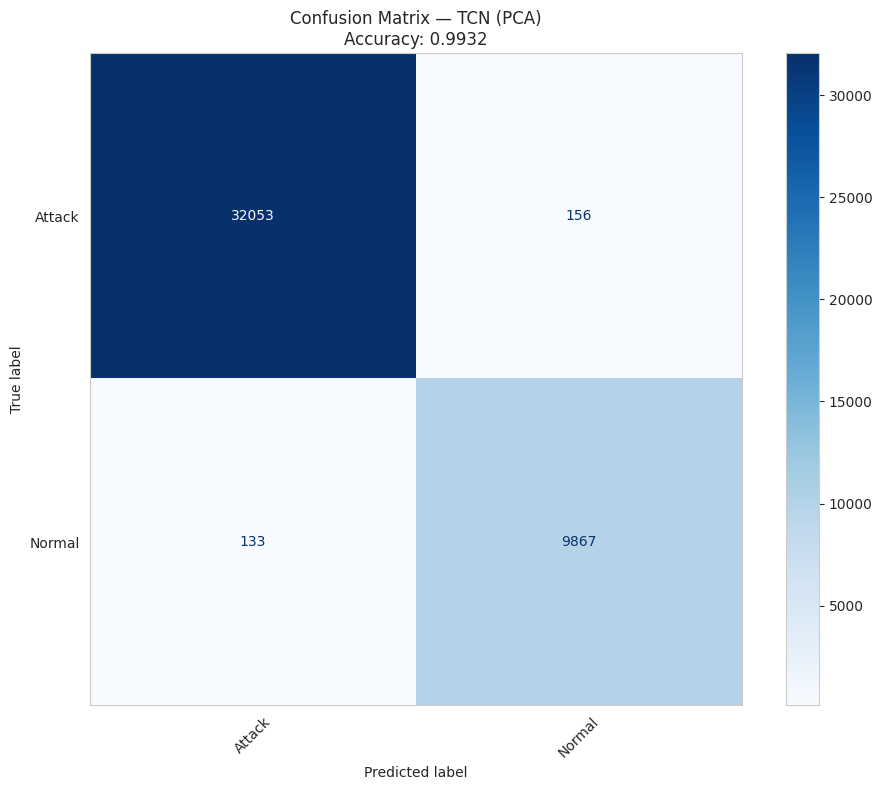

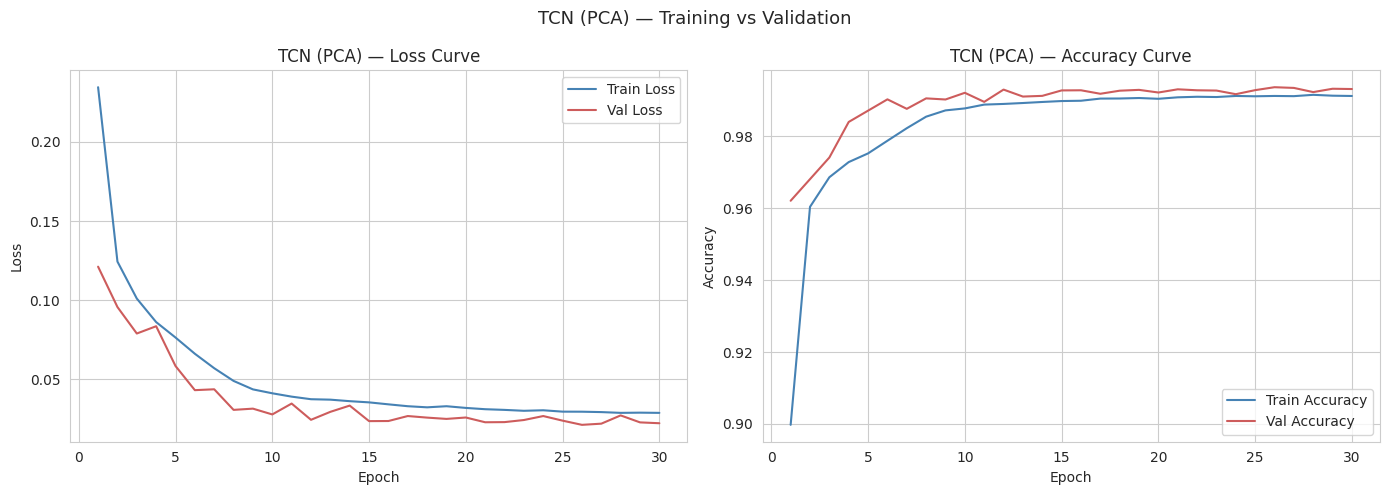

MODEL: TCN (Hybrid FS)
  Epoch 1/30 - train_loss: 0.1973, train_acc: 0.9262, val_loss: 0.0934, val_acc: 0.9722
  Epoch 5/30 - train_loss: 0.0484, train_acc: 0.9860, val_loss: 0.0346, val_acc: 0.9891
  Epoch 10/30 - train_loss: 0.0318, train_acc: 0.9900, val_loss: 0.0246, val_acc: 0.9919
  Epoch 15/30 - train_loss: 0.0278, train_acc: 0.9915, val_loss: 0.0199, val_acc: 0.9931
  Epoch 20/30 - train_loss: 0.0234, train_acc: 0.9925, val_loss: 0.0166, val_acc: 0.9946
  Epoch 25/30 - train_loss: 0.0222, train_acc: 0.9929, val_loss: 0.0147, val_acc: 0.9953
  Epoch 30/30 - train_loss: 0.0202, train_acc: 0.9934, val_loss: 0.0149, val_acc: 0.9951
Accuracy: 0.9950
ROC-AUC: 0.9996   PR-AUC: 0.9998

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00     32209
      Normal       0.99      0.99      0.99     10000

    accuracy                           0.99     42209
   macro avg       0.99      0.99      0.99     42209
weighted a

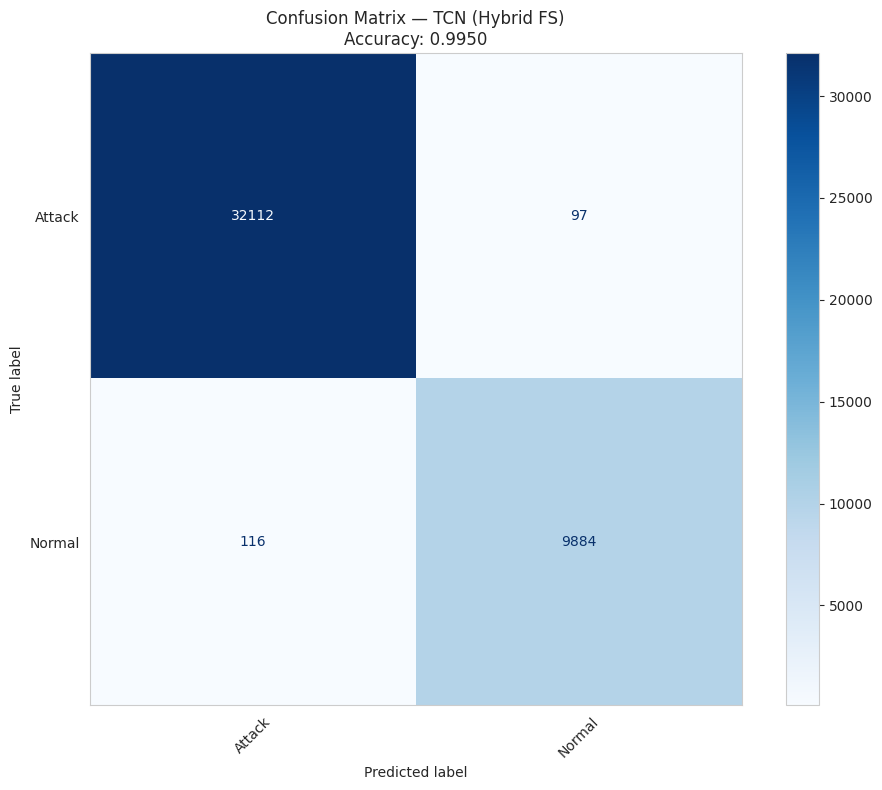

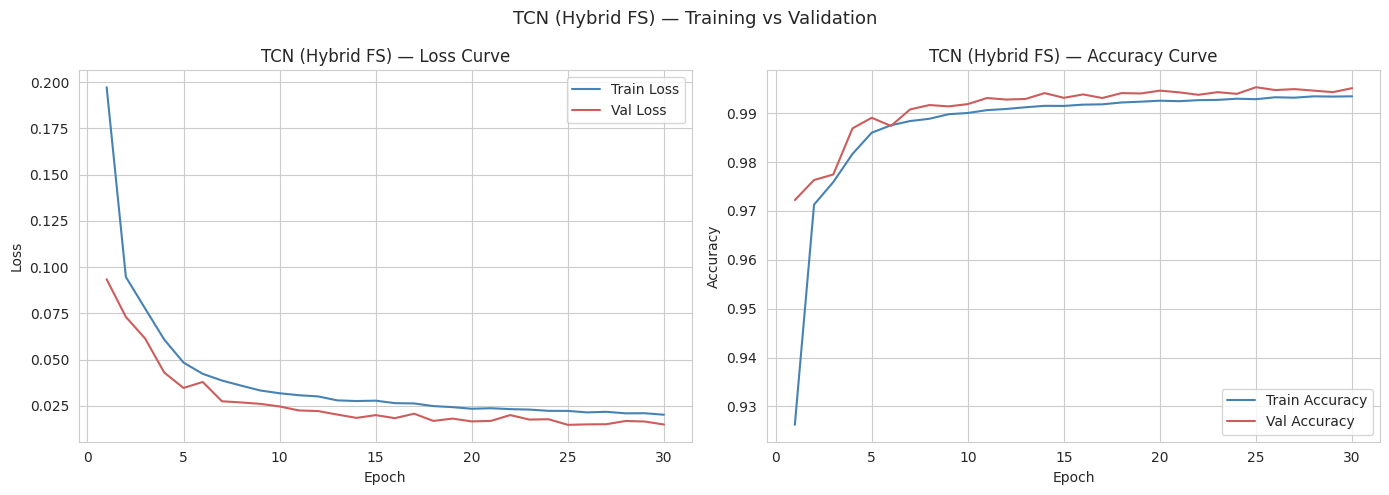

In [ ]:
class Chomp1d(nn.Module):
    """Removes the extra right-side padding introduced by causal (left-only) convolution."""
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        return x[:, :, :-self.chomp_size] if self.chomp_size > 0 else x


class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, dilation, dropout=0.2):
        super().__init__()
        padding = (kernel_size - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(n_inputs, n_outputs, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(n_outputs, n_outputs, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout),
        )
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


class TCNNet(nn.Module):
    def __init__(self, n_classes, channels=(32, 32, 32), kernel_size=3, dropout=0.2):
        super().__init__()
        layers = []
        for i, out_ch in enumerate(channels):
            in_ch = 1 if i == 0 else channels[i - 1]
            layers.append(TemporalBlock(in_ch, out_ch, kernel_size, dilation=2 ** i, dropout=dropout))
        self.tcn = nn.Sequential(*layers)
        self.fc = nn.Linear(channels[-1], n_classes)

    def forward(self, x):  # x: (batch, 1, n_features)
        y = self.tcn(x)
        y = y.mean(dim=2)  # global average pool across the feature "sequence"
        return self.fc(y)


class TCNWrapper:
    """fit/predict adapter around TCNNet, with the same 10%% validation-split /
    per-epoch history pattern used by the other deep models above."""
    def __init__(self, n_features, n_classes, channels=(32, 32, 32), kernel_size=3, dropout=0.2,
                 epochs=30, batch_size=256, lr=1e-3, val_size=0.10, device='cpu', random_state=42):
        self.device = device
        self.net = TCNNet(n_classes, channels=channels, kernel_size=kernel_size, dropout=dropout).to(device)
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.val_size = val_size
        self.random_state = random_state
        self.history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    def _forward(self, X):
        X_t = torch.tensor(X, dtype=torch.float32).unsqueeze(1).to(self.device)  # (N, 1, F)
        return self.net(X_t)

    def fit(self, X, y):
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_size, random_state=self.random_state, stratify=y
        )
        X_tr_t = torch.tensor(X_tr, dtype=torch.float32).unsqueeze(1).to(self.device)
        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(self.device)

        opt = optim.Adam(self.net.parameters(), lr=self.lr)
        loss_fn = nn.CrossEntropyLoss()
        n = X_tr_t.shape[0]

        for epoch in range(self.epochs):
            self.net.train()
            perm = torch.randperm(n)
            running_loss, correct = 0.0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                logits = self.net(X_tr_t[idx])
                loss = loss_fn(logits, y_tr_t[idx])
                loss.backward()
                opt.step()
                running_loss += loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == y_tr_t[idx]).sum().item()
            train_loss = running_loss / n
            train_acc = correct / n

            self.net.eval()
            with torch.no_grad():
                val_logits = self._forward(X_val)
                val_loss = loss_fn(val_logits, y_val_t).item()
                val_acc = (val_logits.argmax(dim=1) == y_val_t).float().mean().item()

            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            self.history['train_acc'].append(train_acc)
            self.history['val_acc'].append(val_acc)

            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f'  Epoch {epoch + 1}/{self.epochs} - '
                      f'train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, '
                      f'val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            return torch.softmax(self._forward(X), dim=1).cpu().numpy()

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


tcn_model_pca = TCNWrapper(
    n_features=X_train_pca.shape[1], n_classes=len(class_names), device=device
)
tcn_acc_pca = evaluate_model('TCN (PCA)', tcn_model_pca, X_train_pca, X_test_pca, y_train, y_test, class_names)
plot_train_val_curves(tcn_model_pca.history, 'TCN (PCA)')

tcn_model_fs = TCNWrapper(
    n_features=X_train_fs.shape[1], n_classes=len(class_names), device=device
)
tcn_acc_fs = evaluate_model('TCN (Hybrid FS)', tcn_model_fs, X_train_fs, X_test_fs, y_train, y_test, class_names)
plot_train_val_curves(tcn_model_fs.history, 'TCN (Hybrid FS)')


## 5-Fold Stratified Cross-Validation (All Models)

CV is run on the **Hybrid Feature-Selection** representation (`X_train_fs` / `y_train`), entirely within the training split — the held-out test set (`X_test_fs` / `y_test`) stays untouched for the single-split evaluation reported above. The same `StratifiedKFold` object is reused for every model so all 7 models see **identical folds**, which is required for the paired significance tests that follow.

In [ ]:
from sklearn.model_selection import StratifiedKFold
from scipy import stats

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

def run_kfold_cv(name, model_factory, X, y, skf, verbose=True):
    """Stratified K-Fold CV. model_factory() must return a *fresh*, unfitted
    model instance on every call. Returns an array of per-fold accuracy scores
    (used later for the significance tests)."""
    fold_scores = []
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
        X_tr, X_val = X[tr_idx], X[val_idx]
        y_tr, y_val = y[tr_idx], y[val_idx]
        model = model_factory()
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        acc = accuracy_score(y_val, preds)
        fold_scores.append(acc)
        if verbose:
            print(f'  Fold {fold}/{N_SPLITS}: accuracy = {acc:.4f}')
    fold_scores = np.array(fold_scores)
    print(f'{name} \u2014 5-Fold CV Accuracy: {fold_scores.mean():.4f} \u00b1 {fold_scores.std():.4f}')
    return fold_scores


In [ ]:
# Re-running 5-fold CV for the 3 deep models is compute-heavy (5 folds x N epochs each).
# DL_CV_EPOCHS is kept lower than the main single-split run (30) to keep this tractable;
# raise it back to 30 if you have the compute budget / time.
DL_CV_EPOCHS = 15

model_factories = {
    'Random Forest': lambda: RandomForestClassifier(
        n_estimators=50, min_samples_leaf=2, random_state=42, n_jobs=-1),
    'KNN': lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'XGBoost': lambda: XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=6,
        use_label_encoder=False, eval_metric='logloss', random_state=42, n_jobs=-1),
    'CatBoost': lambda: CatBoostClassifier(
        iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42),
    'TabTransformer': lambda: TabTransformerWrapper(
        n_features=X_train_fs.shape[1], n_classes=len(class_names),
        epochs=DL_CV_EPOCHS, device=device),
    'Autoencoder Classifier': lambda: AutoencoderClassifierWrapper(
        n_features=X_train_fs.shape[1], n_classes=len(class_names),
        epochs=DL_CV_EPOCHS, device=device),
    'TCN': lambda: TCNWrapper(
        n_features=X_train_fs.shape[1], n_classes=len(class_names),
        epochs=DL_CV_EPOCHS, device=device),
}

cv_scores = {}
for name, factory in model_factories.items():
    print('=' * 70)
    print(f'5-FOLD CV: {name}')
    print('=' * 70)
    cv_scores[name] = run_kfold_cv(name, factory, X_train_fs, y_train, skf)
    print()


5-FOLD CV: Random Forest
  Fold 1/5: accuracy = 0.9993
  Fold 2/5: accuracy = 0.9995
  Fold 3/5: accuracy = 0.9994
  Fold 4/5: accuracy = 0.9995
  Fold 5/5: accuracy = 0.9994
Random Forest — 5-Fold CV Accuracy: 0.9994 ± 0.0001

5-FOLD CV: KNN
  Fold 1/5: accuracy = 0.9970
  Fold 2/5: accuracy = 0.9971
  Fold 3/5: accuracy = 0.9977
  Fold 4/5: accuracy = 0.9973
  Fold 5/5: accuracy = 0.9971
KNN — 5-Fold CV Accuracy: 0.9972 ± 0.0002

5-FOLD CV: XGBoost
  Fold 1/5: accuracy = 0.9989
  Fold 2/5: accuracy = 0.9990
  Fold 3/5: accuracy = 0.9991
  Fold 4/5: accuracy = 0.9992
  Fold 5/5: accuracy = 0.9992
XGBoost — 5-Fold CV Accuracy: 0.9991 ± 0.0001

5-FOLD CV: CatBoost
  Fold 1/5: accuracy = 0.9987
  Fold 2/5: accuracy = 0.9988
  Fold 3/5: accuracy = 0.9986
  Fold 4/5: accuracy = 0.9987
  Fold 5/5: accuracy = 0.9989
CatBoost — 5-Fold CV Accuracy: 0.9987 ± 0.0001

5-FOLD CV: TabTransformer
  Epoch 1/15 - train_loss: 0.1163, train_acc: 0.9622, val_loss: 0.0610, val_acc: 0.9793
  Epoch 5/15 - t

                 Model  Mean Accuracy  Std Dev
         Random Forest       0.999410 0.000090
               XGBoost       0.999103 0.000116
              CatBoost       0.998735 0.000115
                   KNN       0.997229 0.000237
        TabTransformer       0.993876 0.000597
Autoencoder Classifier       0.993713 0.000183
                   TCN       0.992626 0.000538


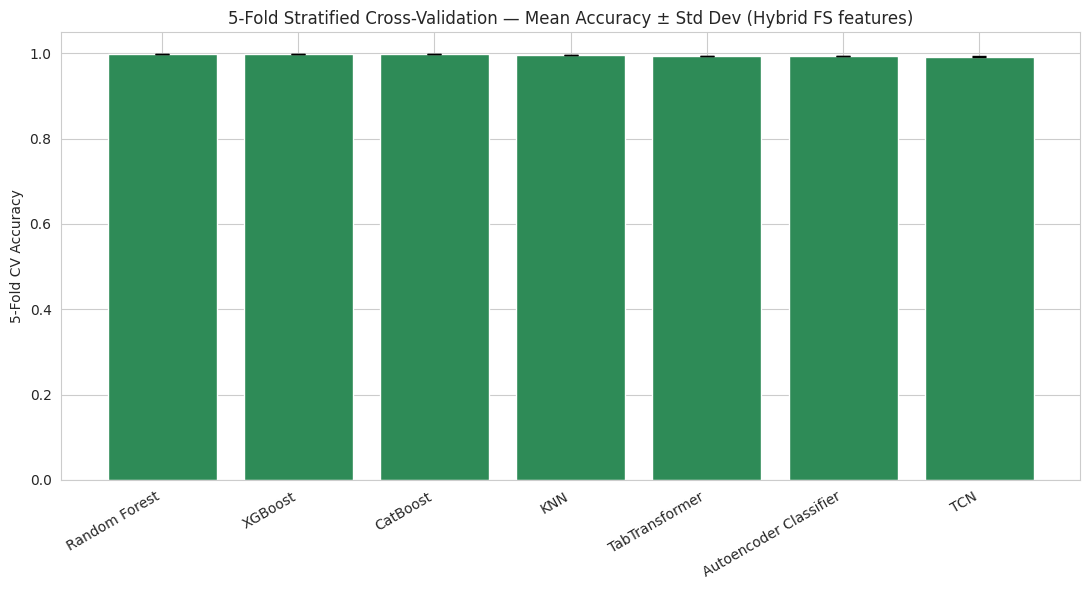

In [ ]:
cv_summary = pd.DataFrame({
    'Model': list(cv_scores.keys()),
    'Mean Accuracy': [cv_scores[m].mean() for m in cv_scores],
    'Std Dev': [cv_scores[m].std() for m in cv_scores],
}).sort_values('Mean Accuracy', ascending=False).reset_index(drop=True)
print(cv_summary.to_string(index=False))

plt.figure(figsize=(11, 6))
plt.bar(cv_summary['Model'], cv_summary['Mean Accuracy'],
        yerr=cv_summary['Std Dev'], capsize=5, color='seagreen')
plt.ylabel('5-Fold CV Accuracy')
plt.title('5-Fold Stratified Cross-Validation \u2014 Mean Accuracy \u00b1 Std Dev (Hybrid FS features)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## Final Model Comparison

                 Model  PCA Accuracy  Hybrid FS Accuracy  Improvement (FS - PCA)
         Random Forest      0.998010            0.999076                0.001066
               XGBoost      0.996920            0.998697                0.001777
              CatBoost      0.996754            0.998436                0.001682
                   KNN      0.997489            0.997489                0.000000
        TabTransformer      0.995404            0.995214               -0.000190
                   TCN      0.993153            0.994954                0.001801
Autoencoder Classifier      0.995096            0.994788               -0.000308


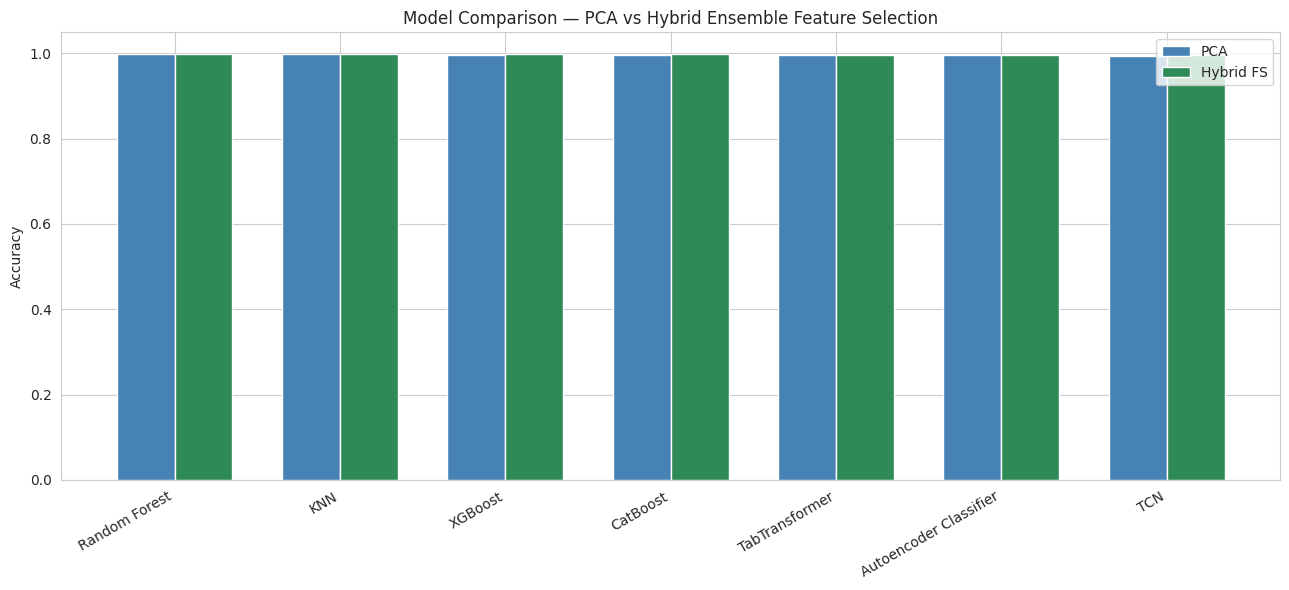

In [ ]:
results_pca = {
    'Random Forest': rf_acc_pca,
    'KNN': knn_acc_pca,
    'XGBoost': xgb_acc_pca,
    'CatBoost': cat_acc_pca,
    'TabTransformer': tabtransformer_acc_pca,
    'Autoencoder Classifier': ae_acc_pca,
    'TCN': tcn_acc_pca,
}

results_fs = {
    'Random Forest': rf_acc_fs,
    'KNN': knn_acc_fs,
    'XGBoost': xgb_acc_fs,
    'CatBoost': cat_acc_fs,
    'TabTransformer': tabtransformer_acc_fs,
    'Autoencoder Classifier': ae_acc_fs,
    'TCN': tcn_acc_fs,
}

model_names = list(results_pca.keys())
res_df = pd.DataFrame({
    'Model': model_names,
    'PCA Accuracy': [results_pca[m] for m in model_names],
    'Hybrid FS Accuracy': [results_fs[m] for m in model_names],
})
res_df['Improvement (FS - PCA)'] = res_df['Hybrid FS Accuracy'] - res_df['PCA Accuracy']
res_df = res_df.sort_values('Hybrid FS Accuracy', ascending=False)
print(res_df.to_string(index=False))

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width / 2, [results_pca[m] for m in model_names], width, label='PCA', color='steelblue')
ax.bar(x + width / 2, [results_fs[m] for m in model_names], width, label='Hybrid FS', color='seagreen')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=30, ha='right')
ax.set_ylabel('Accuracy')
ax.set_title('Model Comparison — PCA vs Hybrid Ensemble Feature Selection')
ax.legend()
plt.tight_layout()
plt.show()


## Explainable AI (XAI) -- SHAP for the Best Model

Identifies the single best-performing (model, feature-set) combination from the comparison above, and applies SHAP to explain its predictions:
- **Tree models** (Random Forest, XGBoost, CatBoost) -> `shap.TreeExplainer` (exact, fast).
- **Everything else** (KNN, TabTransformer, Autoencoder Classifier, TCN) -> `shap.KernelExplainer` as a model-agnostic fallback (slower, so run on a subsample).

SHAP values are computed for the **Attack** class (positive class) so a positive SHAP value pushes a prediction toward *Attack* and a negative value pushes it toward *Normal*.

In [ ]:
# Install SHAP (already installed earlier in the notebook if that cell was run; safe to repeat)
!pip install -q shap


In [ ]:
import shap

# --- Identify the best (model, feature-set) combination from res_df ---
model_lookup = {
    ('Random Forest', 'PCA'): rf_pca,
    ('Random Forest', 'Hybrid FS'): rf_fs,
    ('KNN', 'PCA'): knn_pca,
    ('KNN', 'Hybrid FS'): knn_fs,
    ('XGBoost', 'PCA'): xgb_pca,
    ('XGBoost', 'Hybrid FS'): xgb_fs,
    ('CatBoost', 'PCA'): cat_pca,
    ('CatBoost', 'Hybrid FS'): cat_fs,
    ('TabTransformer', 'PCA'): tabtransformer_model_pca,
    ('TabTransformer', 'Hybrid FS'): tabtransformer_model_fs,
    ('Autoencoder Classifier', 'PCA'): ae_model_pca,
    ('Autoencoder Classifier', 'Hybrid FS'): ae_model_fs,
    ('TCN', 'PCA'): tcn_model_pca,
    ('TCN', 'Hybrid FS'): tcn_model_fs,
}

data_lookup = {
    'PCA': (X_train_pca, X_test_pca, component_labels),
    'Hybrid FS': (X_train_fs, X_test_fs, selected_features),
}

melted = res_df.melt(
    id_vars='Model',
    value_vars=['PCA Accuracy', 'Hybrid FS Accuracy'],
    var_name='Feature Set',
    value_name='Accuracy',
)
melted['Feature Set'] = melted['Feature Set'].str.replace(' Accuracy', '', regex=False)
best_row = melted.sort_values('Accuracy', ascending=False).iloc[0]

best_model_name = best_row['Model']
best_feature_set = best_row['Feature Set']
best_accuracy = best_row['Accuracy']

best_model = model_lookup[(best_model_name, best_feature_set)]
X_train_best, X_test_best, feature_names_best = data_lookup[best_feature_set]

print(f'Best model overall: {best_model_name} ({best_feature_set} features) '
      f'-- Accuracy: {best_accuracy:.4f}')


Best model overall: Random Forest (Hybrid FS features) -- Accuracy: 0.9991


In [ ]:
# --- Compute SHAP values for the best model ---
TREE_MODELS = ('Random Forest', 'XGBoost', 'CatBoost')

# Subsample for speed (KernelExplainer especially does not scale to full data)
SHAP_BG_N = min(200, len(X_train_best))
SHAP_EXPLAIN_N = min(500, len(X_test_best))

rng = np.random.RandomState(42)
bg_idx = rng.choice(len(X_train_best), size=SHAP_BG_N, replace=False)
explain_idx = rng.choice(len(X_test_best), size=SHAP_EXPLAIN_N, replace=False)

X_bg_df = pd.DataFrame(X_train_best[bg_idx], columns=feature_names_best)
X_explain_df = pd.DataFrame(X_test_best[explain_idx], columns=feature_names_best)

pos_idx = list(class_names).index('Attack') if 'Attack' in class_names else 1

if best_model_name in TREE_MODELS:
    explainer = shap.TreeExplainer(best_model)
    raw_shap = explainer.shap_values(X_explain_df)

    if isinstance(raw_shap, list):
        # list of per-class arrays -> take the Attack (positive) class
        shap_values = raw_shap[pos_idx]
        base_value = explainer.expected_value[pos_idx]
    else:
        shap_arr = np.array(raw_shap)
        if shap_arr.ndim == 3:
            # (n_samples, n_features, n_classes)
            shap_values = shap_arr[:, :, pos_idx]
            base_value = np.array(explainer.expected_value).reshape(-1)[pos_idx]
        else:
            shap_values = shap_arr
            base_value = explainer.expected_value
            if isinstance(base_value, (list, np.ndarray)):
                base_value = np.array(base_value).reshape(-1)[-1]
    explainer_used = 'TreeExplainer'
else:
    predict_fn = lambda x: best_model.predict_proba(np.asarray(x))[:, pos_idx]
    explainer = shap.KernelExplainer(predict_fn, X_bg_df)
    shap_values = explainer.shap_values(X_explain_df, nsamples=100)
    shap_values = np.array(shap_values)
    base_value = explainer.expected_value
    if isinstance(base_value, (list, np.ndarray)):
        base_value = np.array(base_value).reshape(-1)[0]
    explainer_used = 'KernelExplainer'

print(f'SHAP values computed for {best_model_name} ({best_feature_set}) using {explainer_used}')
print('shap_values shape:', shap_values.shape)


SHAP values computed for Random Forest (Hybrid FS) using TreeExplainer
shap_values shape: (500, 20)


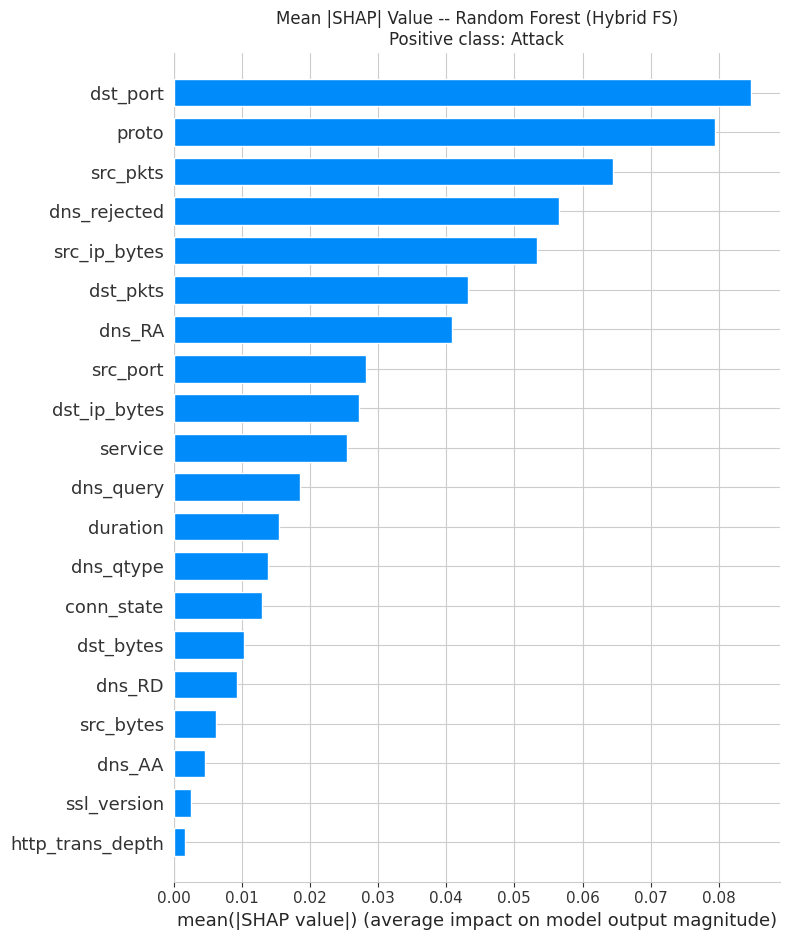

In [ ]:
# --- Global explainability: mean |SHAP| feature importance ---
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_explain_df, plot_type='bar', show=False)
plt.title(f'Mean |SHAP| Value -- {best_model_name} ({best_feature_set})\nPositive class: Attack')
plt.tight_layout()
plt.show()


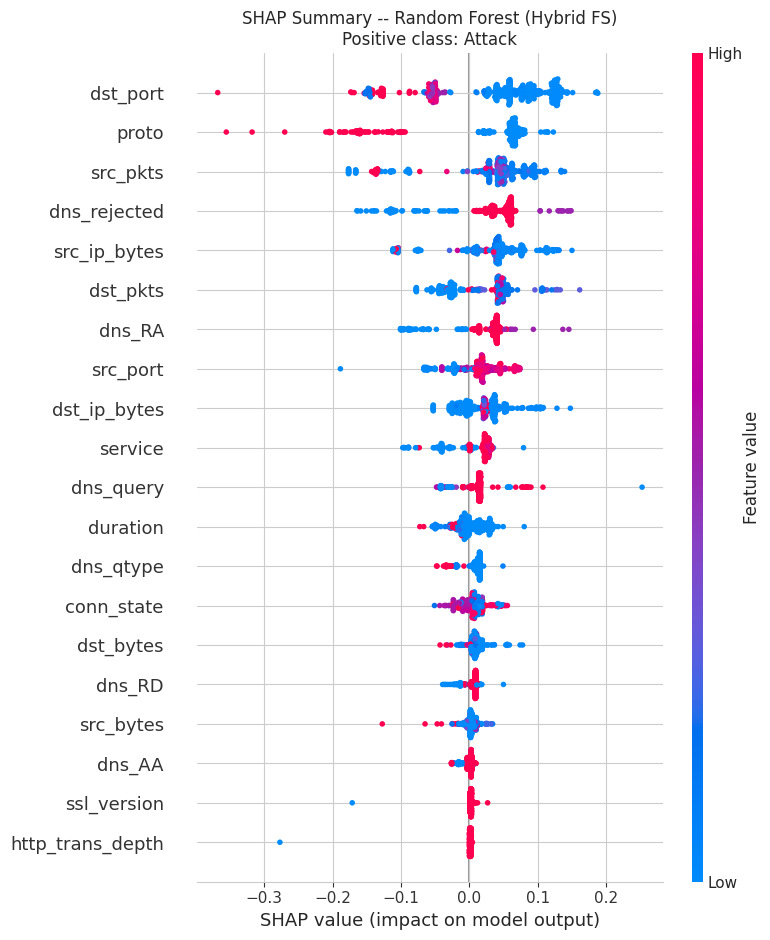

In [ ]:
# --- Global explainability: SHAP beeswarm (direction + magnitude per feature) ---
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_explain_df, show=False)
plt.title(f'SHAP Summary -- {best_model_name} ({best_feature_set})\nPositive class: Attack')
plt.tight_layout()
plt.show()


In [ ]:
# --- Ranked feature importance table (top 15) ---
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_importance_df = pd.DataFrame({
    'Feature': feature_names_best,
    'Mean |SHAP|': mean_abs_shap,
}).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)

print(f'Top-15 most influential features -- {best_model_name} ({best_feature_set})')
print(shap_importance_df.head(15).to_string(index=False))


Top-15 most influential features -- Random Forest (Hybrid FS)
     Feature  Mean |SHAP|
    dst_port     0.084737
       proto     0.079418
    src_pkts     0.064524
dns_rejected     0.056571
src_ip_bytes     0.053262
    dst_pkts     0.043215
      dns_RA     0.040859
    src_port     0.028225
dst_ip_bytes     0.027215
     service     0.025414
   dns_query     0.018497
    duration     0.015426
   dns_qtype     0.013837
  conn_state     0.012947
   dst_bytes     0.010395


### Local Explanation -- Individual Predictions

Waterfall plots for one predicted **Attack** sample and one predicted **Normal** sample, showing exactly which features pushed that individual prediction away from the base rate.

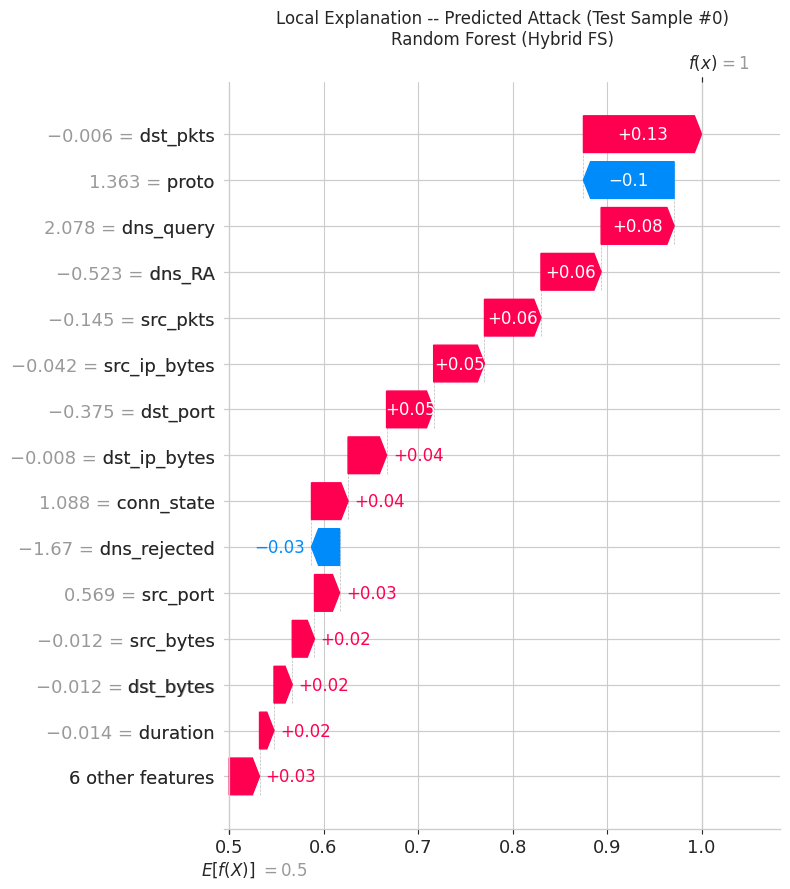

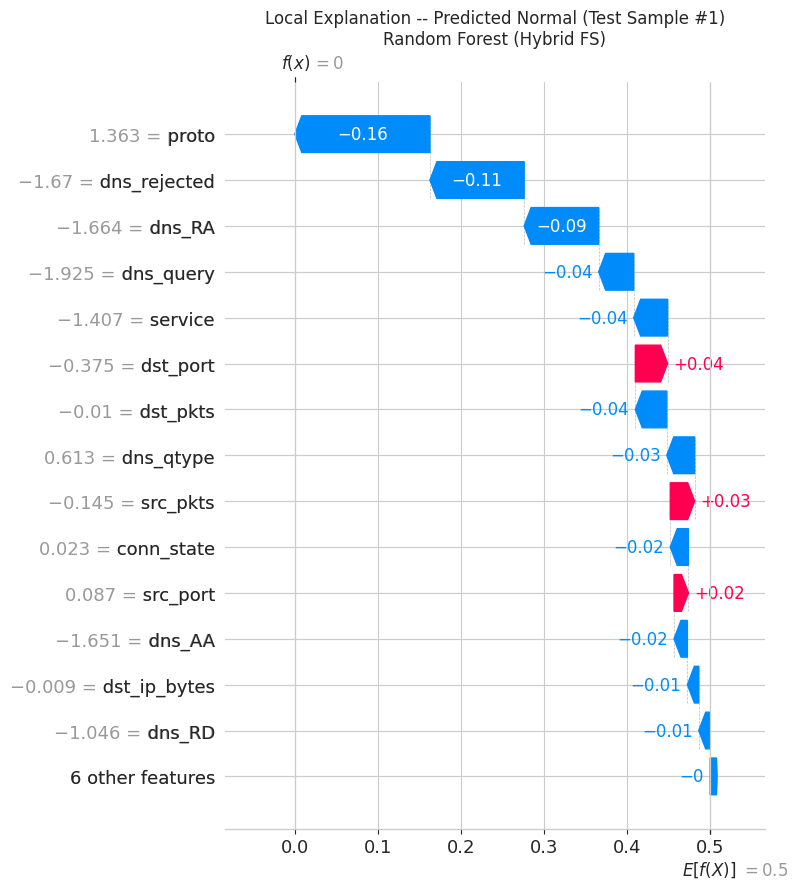

In [ ]:
# --- Local explainability: waterfall plots for one Attack and one Normal prediction ---
y_pred_explain = best_model.predict(X_explain_df.values if hasattr(X_explain_df, 'values') else X_explain_df)

attack_candidates = np.where(y_pred_explain == pos_idx)[0]
normal_candidates = np.where(y_pred_explain != pos_idx)[0]

sample_ids = []
if len(attack_candidates) > 0:
    sample_ids.append(('Attack', attack_candidates[0]))
if len(normal_candidates) > 0:
    sample_ids.append(('Normal', normal_candidates[0]))

for label, sample_i in sample_ids:
    exp = shap.Explanation(
        values=shap_values[sample_i],
        base_values=base_value,
        data=X_explain_df.iloc[sample_i].values,
        feature_names=feature_names_best,
    )
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(exp, show=False, max_display=15)
    plt.title(f'Local Explanation -- Predicted {label} (Test Sample #{sample_i})\n'
              f'{best_model_name} ({best_feature_set})')
    plt.tight_layout()
    plt.show()
